# MBTI Student Compatibility Network

Exploratory notebook for our Graph Analytics project. Starting from the 16Personalities survey filled out by classmates, we use the 5 continuous trait scores (`Energy`, `Mind`, `Nature`, `Tactics`, `Identity`) to model student compatibility as a weighted network.

In [1]:
import pandas as pd
import numpy as np
import networkx as nx
import plotly.graph_objects as go
import plotly.io as pio
from plotly.subplots import make_subplots

pio.renderers["png"].scale = 2
pio.renderers.default = "plotly_mimetype+png"

raw = pd.read_csv("mbti_profiles.csv")

rename_cols = {
    "ID mail": "student",
    "MBTI": "mbti",
    "Variante": "variant",
    "Énergie · E (%)": "E",
    "Esprit · N (%)": "N",
    "Nature · T (%)": "T",
    "Tactique · J (%)": "J",
    "Identité · A (%)": "A",
}
traits = ["E", "N", "T", "J", "A"]

df = raw[raw["Complétion"] == "Yes"][list(rename_cols.keys())].rename(columns=rename_cols).copy()
for col in traits:
    df[col] = df[col].str.replace("%", "", regex=False).str.strip().astype(float) / 100.0

df = df.dropna(subset=traits + ["mbti"]).set_index("student")

MBTI_ROLE_GROUPS = {
    "INTJ": ("Analysts (NT)", "#4338CA"),
    "INTP": ("Analysts (NT)", "#7C3AED"),
    "ENTJ": ("Analysts (NT)", "#6D28D9"),
    "ENTP": ("Analysts (NT)", "#A855F7"),
    "INFJ": ("Diplomats (NF)", "#0D9488"),
    "INFP": ("Diplomats (NF)", "#14B8A6"),
    "ENFJ": ("Diplomats (NF)", "#059669"),
    "ENFP": ("Diplomats (NF)", "#10B981"),
    "ISTJ": ("Sentinels (SJ)", "#1D4ED8"),
    "ISFJ": ("Sentinels (SJ)", "#2563EB"),
    "ESTJ": ("Sentinels (SJ)", "#0284C7"),
    "ESFJ": ("Sentinels (SJ)", "#38BDF8"),
    "ISTP": ("Explorers (SP)", "#D97706"),
    "ISFP": ("Explorers (SP)", "#F59E0B"),
    "ESTP": ("Explorers (SP)", "#EA580C"),
    "ESFP": ("Explorers (SP)", "#FB923C"),
}

mbti_types = sorted(df["mbti"].unique())
type_colors = {t: MBTI_ROLE_GROUPS[t][1] for t in mbti_types}

G_base = nx.Graph()
for student, row in df.iterrows():
    G_base.add_node(
        student,
        mbti=row["mbti"],
        variant=row["variant"],
        E=float(row["E"]),
        N=float(row["N"]),
        T=float(row["T"]),
        J=float(row["J"]),
        A=float(row["A"]),
    )


def smart_text_positions(pos, node_order):
    """Assign non-overlapping Plotly textposition per node via greedy clearance maximization."""
    xs = np.array([pos[n][0] for n in node_order])
    ys = np.array([pos[n][1] for n in node_order])
    span_x = max(xs.max() - xs.min(), 1e-6)
    span_y = max(ys.max() - ys.min(), 1e-6)

    nx_coord = {n: (pos[n][0] - xs.min()) / span_x for n in node_order}
    ny_coord = {n: (pos[n][1] - ys.min()) / span_y for n in node_order}

    candidates = [
        ("top center", (0.0, 0.058)),
        ("bottom center", (0.0, -0.062)),
        ("top left", (-0.052, 0.048)),
        ("top right", (0.052, 0.048)),
        ("bottom left", (-0.052, -0.052)),
        ("bottom right", (0.052, -0.052)),
        ("middle left", (-0.072, 0.0)),
        ("middle right", (0.072, 0.0)),
    ]

    crowding = {
        u: min(
            (np.hypot(nx_coord[u] - nx_coord[v], ny_coord[u] - ny_coord[v]) for v in node_order if v != u),
            default=1.0,
        )
        for u in node_order
    }

    placed_labels = []
    chosen = {}
    for u in sorted(node_order, key=lambda n: crowding[n]):
        ux, uy = nx_coord[u], ny_coord[u]
        best_name = "top center"
        best_score = -1e9
        best_pt = (ux, uy + 0.058)
        for idx, (cname, (dx, dy)) in enumerate(candidates):
            lx, ly = ux + dx, uy + dy
            min_node_d = min(
                (np.hypot((lx - nx_coord[v]) / 1.35, (ly - ny_coord[v]) / 0.85) for v in node_order if v != u),
                default=1.0,
            )
            min_lbl_d = (
                min(np.hypot((lx - px) / 1.55, (ly - py) / 0.90) for px, py in placed_labels)
                if placed_labels
                else 1.0
            )
            tie_breaker = 0.012 if idx == 0 else (0.006 if idx == 1 else 0.0)
            score = min(min_node_d, min_lbl_d) + tie_breaker
            if score > best_score:
                best_score = score
                best_name = cname
                best_pt = (lx, ly)
        chosen[u] = best_name
        placed_labels.append(best_pt)
    return chosen


def plot_network(G, pos, title, subtitle=None, highlight_above=None):
    """Render an editorial-grade interactive Plotly network diagram."""
    fig = go.Figure()
    all_nodes = list(G.nodes())
    text_pos = smart_text_positions(pos, all_nodes)

    weights = [d["weight"] for _, _, d in G.edges(data=True)]
    w_min = min(weights) if weights else 0.0
    w_max = max(weights) if weights else 1.0
    w_span = max(w_max - w_min, 1e-6)

    if highlight_above is not None:
        reg_x, reg_y = [], []
        for u, v, d in G.edges(data=True):
            if d["weight"] < highlight_above:
                reg_x.extend([pos[u][0], pos[v][0], None])
                reg_y.extend([pos[u][1], pos[v][1], None])
        if reg_x:
            fig.add_trace(
                go.Scatter(
                    x=reg_x,
                    y=reg_y,
                    mode="lines",
                    line=dict(width=1.35, color="rgba(148, 163, 184, 0.36)"),
                    hoverinfo="skip",
                    name=f"Regular tie (< {highlight_above:.0%})",
                    legendgroup="Edges",
                    legendgrouptitle_text="Tie Strength",
                )
            )

        strong_edges = sorted(
            [(u, v, d["weight"]) for u, v, d in G.edges(data=True) if d["weight"] >= highlight_above],
            key=lambda x: x[2],
        )
        for idx, (u, v, w) in enumerate(strong_edges):
            fig.add_trace(
                go.Scatter(
                    x=[pos[u][0], pos[v][0]],
                    y=[pos[u][1], pos[v][1]],
                    mode="lines",
                    line=dict(width=2.6 + (w - highlight_above) * 26.0, color="rgba(30, 64, 175, 0.82)"),
                    hovertemplate=f"<b>{u} ↔ {v}</b><br>Compatibility: {w:.1%}<extra></extra>",
                    name=f"Strong tie (≥ {highlight_above:.0%})",
                    legendgroup="Edges",
                    showlegend=(idx == len(strong_edges) - 1),
                )
            )
    else:
        tiers = [
            (0.00, 0.34, 1.05, "rgba(148, 163, 184, 0.24)", "Lower tier"),
            (0.34, 0.67, 1.80, "rgba(100, 116, 139, 0.38)", "Medium tier"),
            (0.67, 1.01, 2.75, "rgba(51, 65, 85, 0.56)", "Upper tier"),
        ]
        for lo, hi, lw, col, tier_label in tiers:
            tx, ty = [], []
            for u, v, d in G.edges(data=True):
                norm_w = (d["weight"] - w_min) / w_span
                if lo <= norm_w < hi:
                    tx.extend([pos[u][0], pos[v][0], None])
                    ty.extend([pos[u][1], pos[v][1], None])
            if tx:
                fig.add_trace(
                    go.Scatter(
                        x=tx,
                        y=ty,
                        mode="lines",
                        line=dict(width=lw, color=col),
                        hoverinfo="skip",
                        name=tier_label,
                        legendgroup="Edges",
                        legendgrouptitle_text="Relative Tie Weight" if lo == 0.0 else None,
                    )
                )

    # White halo behind nodes so incident edges stop cleanly outside markers
    fig.add_trace(
        go.Scatter(
            x=[pos[n][0] for n in all_nodes],
            y=[pos[n][1] for n in all_nodes],
            mode="markers",
            marker=dict(size=[26 + 1.7 * G.degree(n) for n in all_nodes], color="#FFFFFF", line=dict(width=0)),
            hoverinfo="skip",
            showlegend=False,
        )
    )

    role_order = ["Analysts (NT)", "Diplomats (NF)", "Sentinels (SJ)", "Explorers (SP)"]
    seen_groups = set()
    strength_map = dict(G.degree(weight="weight"))

    max_deg = max((G.degree(n) for n in all_nodes), default=1) or 1
    node_size = {n: 18.0 + 13.0 * (G.degree(n) / max_deg) for n in all_nodes}
    fig.data[-1].marker.size = [node_size[n] + 6.5 for n in all_nodes]

    for role in role_order:
        for t in [m for m in mbti_types if MBTI_ROLE_GROUPS[m][0] == role]:
            t_nodes = [n for n in all_nodes if G.nodes[n]["mbti"] == t]
            if not t_nodes:
                continue
            hover_texts = [
                f"<b>{n}</b> · {G.nodes[n]['mbti']}{G.nodes[n]['variant']}<br>"
                f"Degree: <b>{G.degree(n)}</b> · Strength: <b>{strength_map[n]:.2f}</b><br>"
                f"<span style='color:#64748B'>E {G.nodes[n]['E']:.0%} · N {G.nodes[n]['N']:.0%} · "
                f"T {G.nodes[n]['T']:.0%} · J {G.nodes[n]['J']:.0%} · A {G.nodes[n]['A']:.0%}</span>"
                for n in t_nodes
            ]
            first_in_group = role not in seen_groups
            seen_groups.add(role)
            fig.add_trace(
                go.Scatter(
                    x=[pos[n][0] for n in t_nodes],
                    y=[pos[n][1] for n in t_nodes],
                    mode="markers",
                    name=f"{t} ({len(t_nodes)})",
                    legendgroup=role,
                    legendgrouptitle_text=role if first_in_group else None,
                    marker=dict(
                        size=[node_size[n] for n in t_nodes],
                        color=type_colors[t],
                        opacity=0.95,
                        line=dict(width=2.3, color="#FFFFFF"),
                    ),
                    hovertemplate="%{customdata}<extra></extra>",
                    customdata=hover_texts,
                )
            )

    # Top-most label layer so node circles never occlude student labels
    fig.add_trace(
        go.Scatter(
            x=[pos[n][0] for n in all_nodes],
            y=[pos[n][1] for n in all_nodes],
            mode="text",
            text=[
                f"<b>{n}</b><br><span style='font-size:9px;color:#475569'>{G.nodes[n]['mbti']}{G.nodes[n]['variant']}</span>"
                for n in all_nodes
            ],
            textposition=[text_pos[n] for n in all_nodes],
            textfont=dict(size=10.5, color="#0F172A", family="Inter, -apple-system, BlinkMacSystemFont, sans-serif"),
            hoverinfo="skip",
            showlegend=False,
        )
    )

    auto_sub = subtitle or (
        f"{G.number_of_nodes()} students · {G.number_of_edges()} edges · "
        f"density = {nx.density(G):.3f} · connected = {nx.is_connected(G)}"
    )

    xs = [pos[n][0] for n in all_nodes]
    ys = [pos[n][1] for n in all_nodes]
    x_pad = (max(xs) - min(xs)) * 0.15
    y_pad = (max(ys) - min(ys)) * 0.17

    fig.update_layout(
        title=dict(
            text=f"<b>{title}</b><br><span style='font-size:12.5px;color:#64748B;font-weight:400'>{auto_sub}</span>",
            x=0.02,
            y=0.96,
            xanchor="left",
            yanchor="top",
            font=dict(size=17, color="#0F172A", family="Inter, -apple-system, BlinkMacSystemFont, sans-serif"),
        ),
        width=980,
        height=680,
        paper_bgcolor="#FFFFFF",
        plot_bgcolor="#F8FAFC",
        font=dict(family="Inter, -apple-system, BlinkMacSystemFont, sans-serif", color="#1E293B"),
        margin=dict(l=24, r=205, t=82, b=24),
        xaxis=dict(
            showgrid=False,
            zeroline=False,
            showticklabels=False,
            range=[min(xs) - x_pad, max(xs) + x_pad],
            linecolor="#E2E8F0",
            linewidth=1,
            mirror=True,
        ),
        yaxis=dict(
            showgrid=False,
            zeroline=False,
            showticklabels=False,
            range=[min(ys) - y_pad, max(ys) + y_pad * 1.15],
            linecolor="#E2E8F0",
            linewidth=1,
            mirror=True,
        ),
        legend=dict(
            x=1.015,
            y=0.99,
            xanchor="left",
            yanchor="top",
            bgcolor="rgba(255,255,255,0.94)",
            bordercolor="#E2E8F0",
            borderwidth=1,
            font=dict(size=11, color="#334155"),
            grouptitlefont=dict(size=11, color="#0F172A", family="Inter, sans-serif"),
            tracegroupgap=8,
        ),
        hoverlabel=dict(
            bgcolor="#FFFFFF",
            bordercolor="#CBD5E1",
            font=dict(size=12, family="Inter, -apple-system, sans-serif", color="#0F172A"),
        ),
    )
    fig.show()


print(f"Loaded {len(df)} complete student profiles.")
df.head(10)

Loaded 23 complete student profiles.
Out[1]: 
            mbti variant     E     N     T     J     A
student                                               
aambos      ENFJ      -T  0.56  0.64  0.40  0.53  0.36
abarcelo    ENTJ      -A  1.00  0.63  0.86  0.78  0.99
aravas      ENTJ      -A  0.67  0.61  0.67  0.67  0.71
aspira      ESTJ      -T  0.51  0.46  0.64  0.81  0.33
bledoyen    ENTJ      -A  0.51  0.73  0.69  0.54  0.51
booi        ENTJ      -A  0.52  0.61  0.54  0.54  0.69
cdefosseux  ESFJ      -T  0.54  0.45  0.39  0.57  0.49
enatali     INFJ      -T  0.46  0.64  0.49  0.57  0.39
gbalou      ENTJ      -T  0.65  0.85  0.63  0.67  0.49
grabeau     INTJ      -A  0.43  0.70  0.74  0.72  0.64


,mbti,variant,E,N,T,J,A
student,,,,,,,
aambos,ENFJ,-T,0.56,0.64,0.40,0.53,0.36
abarcelo,ENTJ,-A,1.00,0.63,0.86,0.78,0.99
aravas,ENTJ,-A,0.67,0.61,0.67,0.67,0.71
aspira,ESTJ,-T,0.51,0.46,0.64,0.81,0.33
bledoyen,ENTJ,-A,0.51,0.73,0.69,0.54,0.51
booi,ENTJ,-A,0.52,0.61,0.54,0.54,0.69
cdefosseux,ESFJ,-T,0.54,0.45,0.39,0.57,0.49
enatali,INFJ,-T,0.46,0.64,0.49,0.57,0.39
gbalou,ENTJ,-T,0.65,0.85,0.63,0.67,0.49


## 1. Baseline: Trait Similarity Graph

As a first baseline, we link any two students whose average difference across the 5 traits is at most 20 percentage points (`similarity >= 0.80`).

Similarity graph: 23 nodes, 140 edges (density = 0.55)


,Student A,MBTI A,Student B,MBTI B,Similarity (%)
0,aambos,ENFJ,enatali,INFJ,94.8
1,tgillot,ENFP,zaich,ENFP,94.6
2,aspira,ESTJ,lchapoton,ESTJ,93.0
3,aambos,ENFJ,cdefosseux,ESFJ,92.2
4,aravas,ENTJ,booi,ENTJ,91.4
5,aspira,ESTJ,kechang,ISFJ,91.0
6,bledoyen,ENTJ,booi,ENTJ,90.8
7,bledoyen,ENTJ,gbalou,ENTJ,90.6
8,mzapata,INTP,tfoussard,ENTP,90.6
9,aravas,ENTJ,rlevasseur,ENTJ,90.6


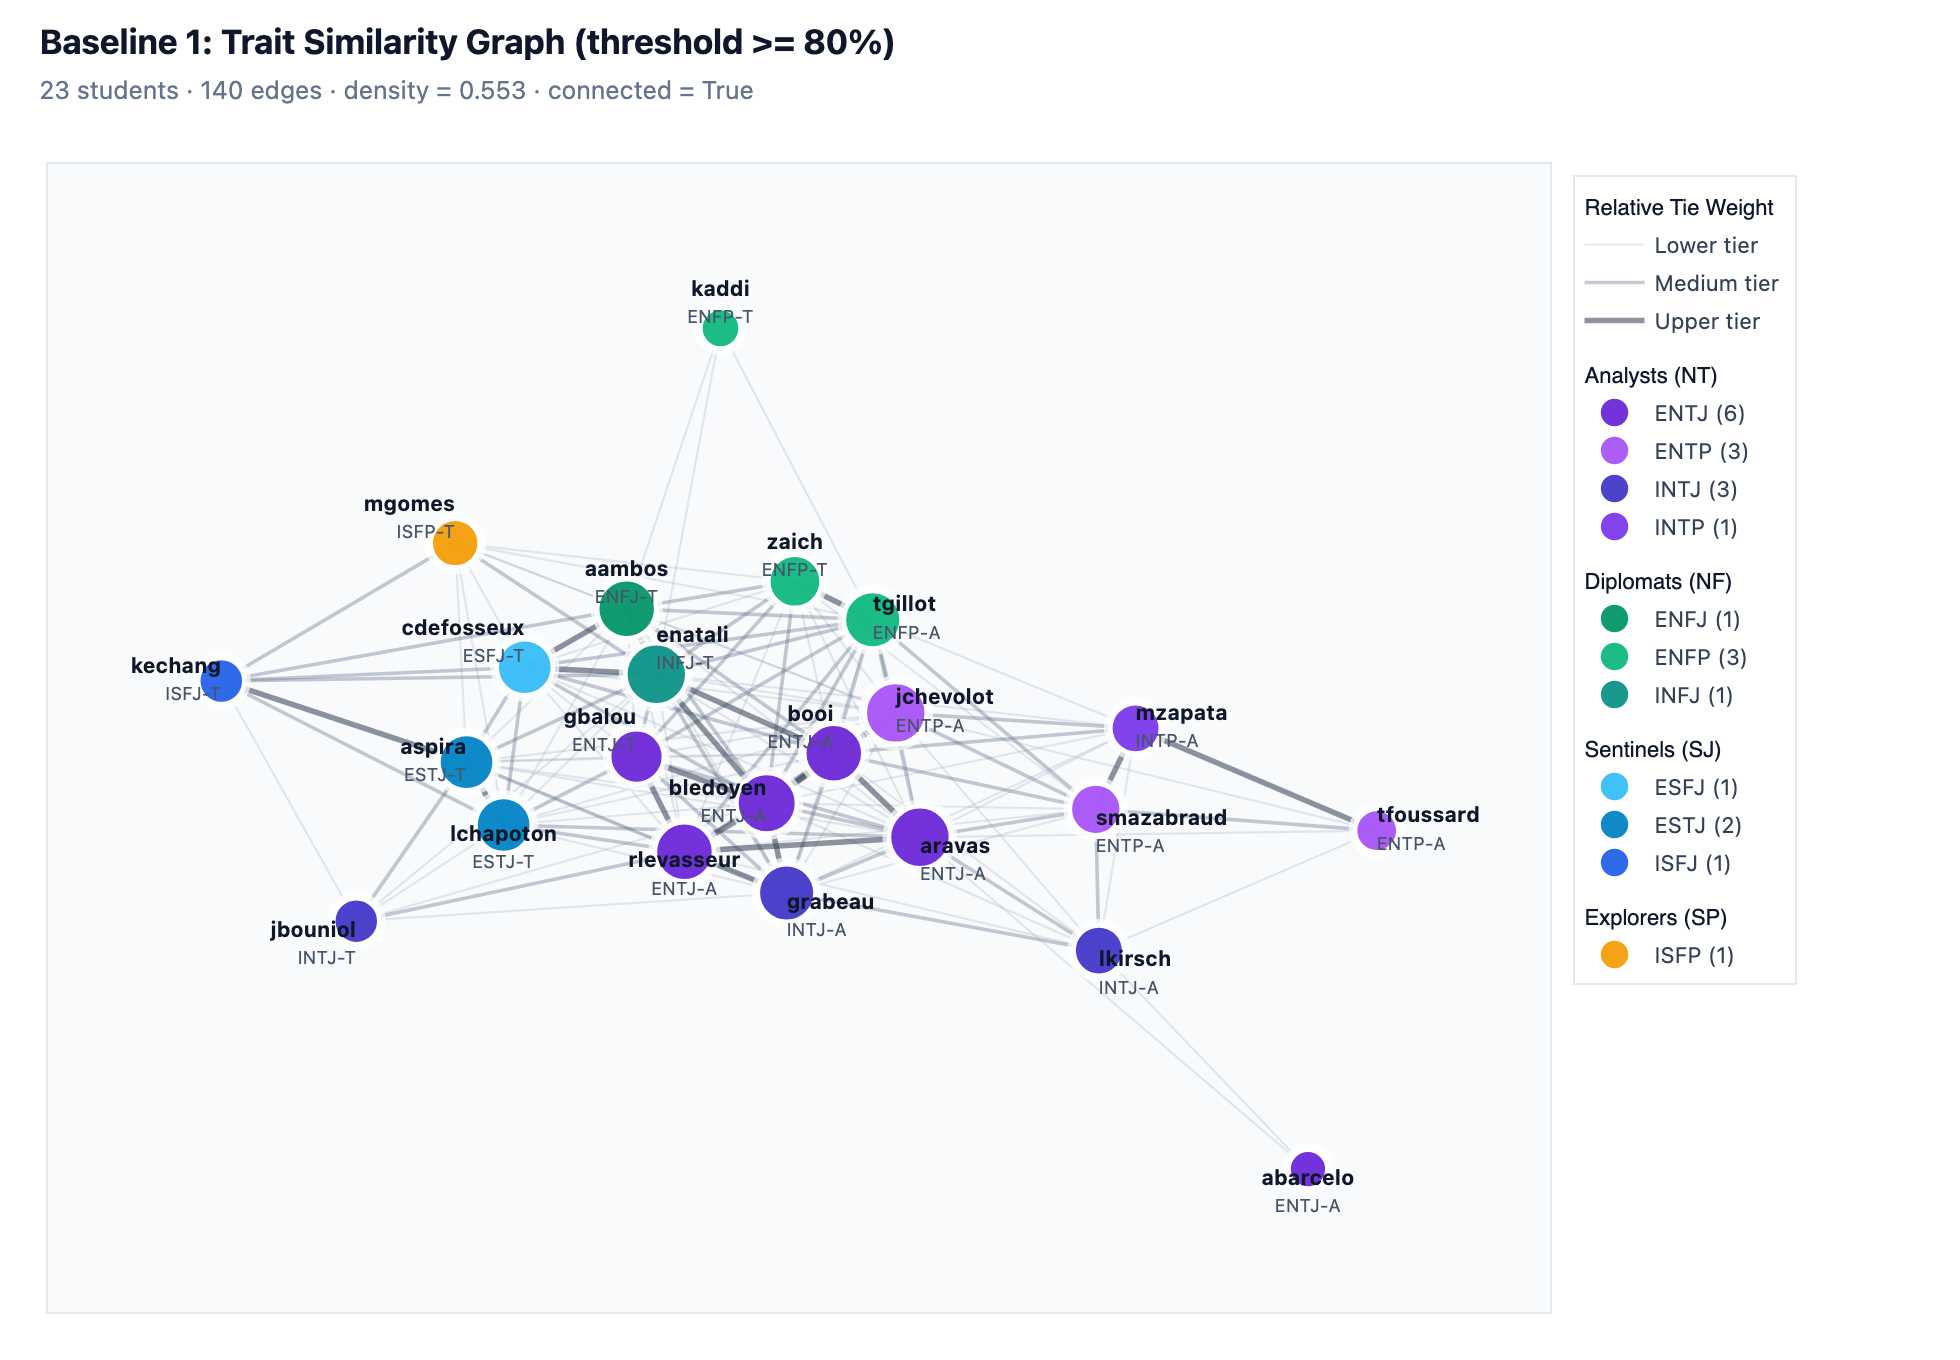

In [2]:
G_sim = G_base.copy()
students = df.index.tolist()
threshold = 0.80
sim_pairs = []

for i in range(len(students)):
    for j in range(i + 1, len(students)):
        u, v = students[i], students[j]
        diff = np.abs(df.loc[u, traits].values - df.loc[v, traits].values)
        sim = float(1.0 - diff.mean())
        if sim >= threshold:
            G_sim.add_edge(u, v, weight=sim)
            sim_pairs.append({
                "Student A": u, "MBTI A": df.loc[u, "mbti"],
                "Student B": v, "MBTI B": df.loc[v, "mbti"],
                "Similarity (%)": round(sim * 100, 1),
            })

sim_df = pd.DataFrame(sim_pairs).sort_values("Similarity (%)", ascending=False).reset_index(drop=True)
print(f"Similarity graph: {G_sim.number_of_nodes()} nodes, {G_sim.number_of_edges()} edges (density = {nx.density(G_sim):.2f})")
display(sim_df.head(10))

pos_sim = nx.spring_layout(G_sim, seed=42, k=1.25, iterations=200, weight="weight")
plot_network(G_sim, pos_sim, "Baseline 1: Trait Similarity Graph (threshold >= 80%)")

## 2. Baseline: Trait Contrast Graph

Here we test the opposite intuition: connecting students who sit on opposite sides of the 50% mark on the 5 dimensions. We keep the top 5 most contrasting links per student.

Contrast graph: 23 nodes, 87 edges


,Student A,MBTI A,Student B,MBTI B,Contrast (%)
0,abarcelo,ENTJ,kaddi,ENFP,24.8
1,kaddi,ENFP,lkirsch,INTJ,23.0
2,kaddi,ENFP,tfoussard,ENTP,21.0
3,abarcelo,ENTJ,mgomes,ISFP,19.8
4,abarcelo,ENTJ,jbouniol,INTJ,15.9
5,kaddi,ENFP,smazabraud,ENTP,15.6
6,abarcelo,ENTJ,kechang,ISFJ,15.4
7,kechang,ISFJ,tfoussard,ENTP,15.2
8,kaddi,ENFP,mzapata,INTP,14.4
9,jbouniol,INTJ,tfoussard,ENTP,14.1


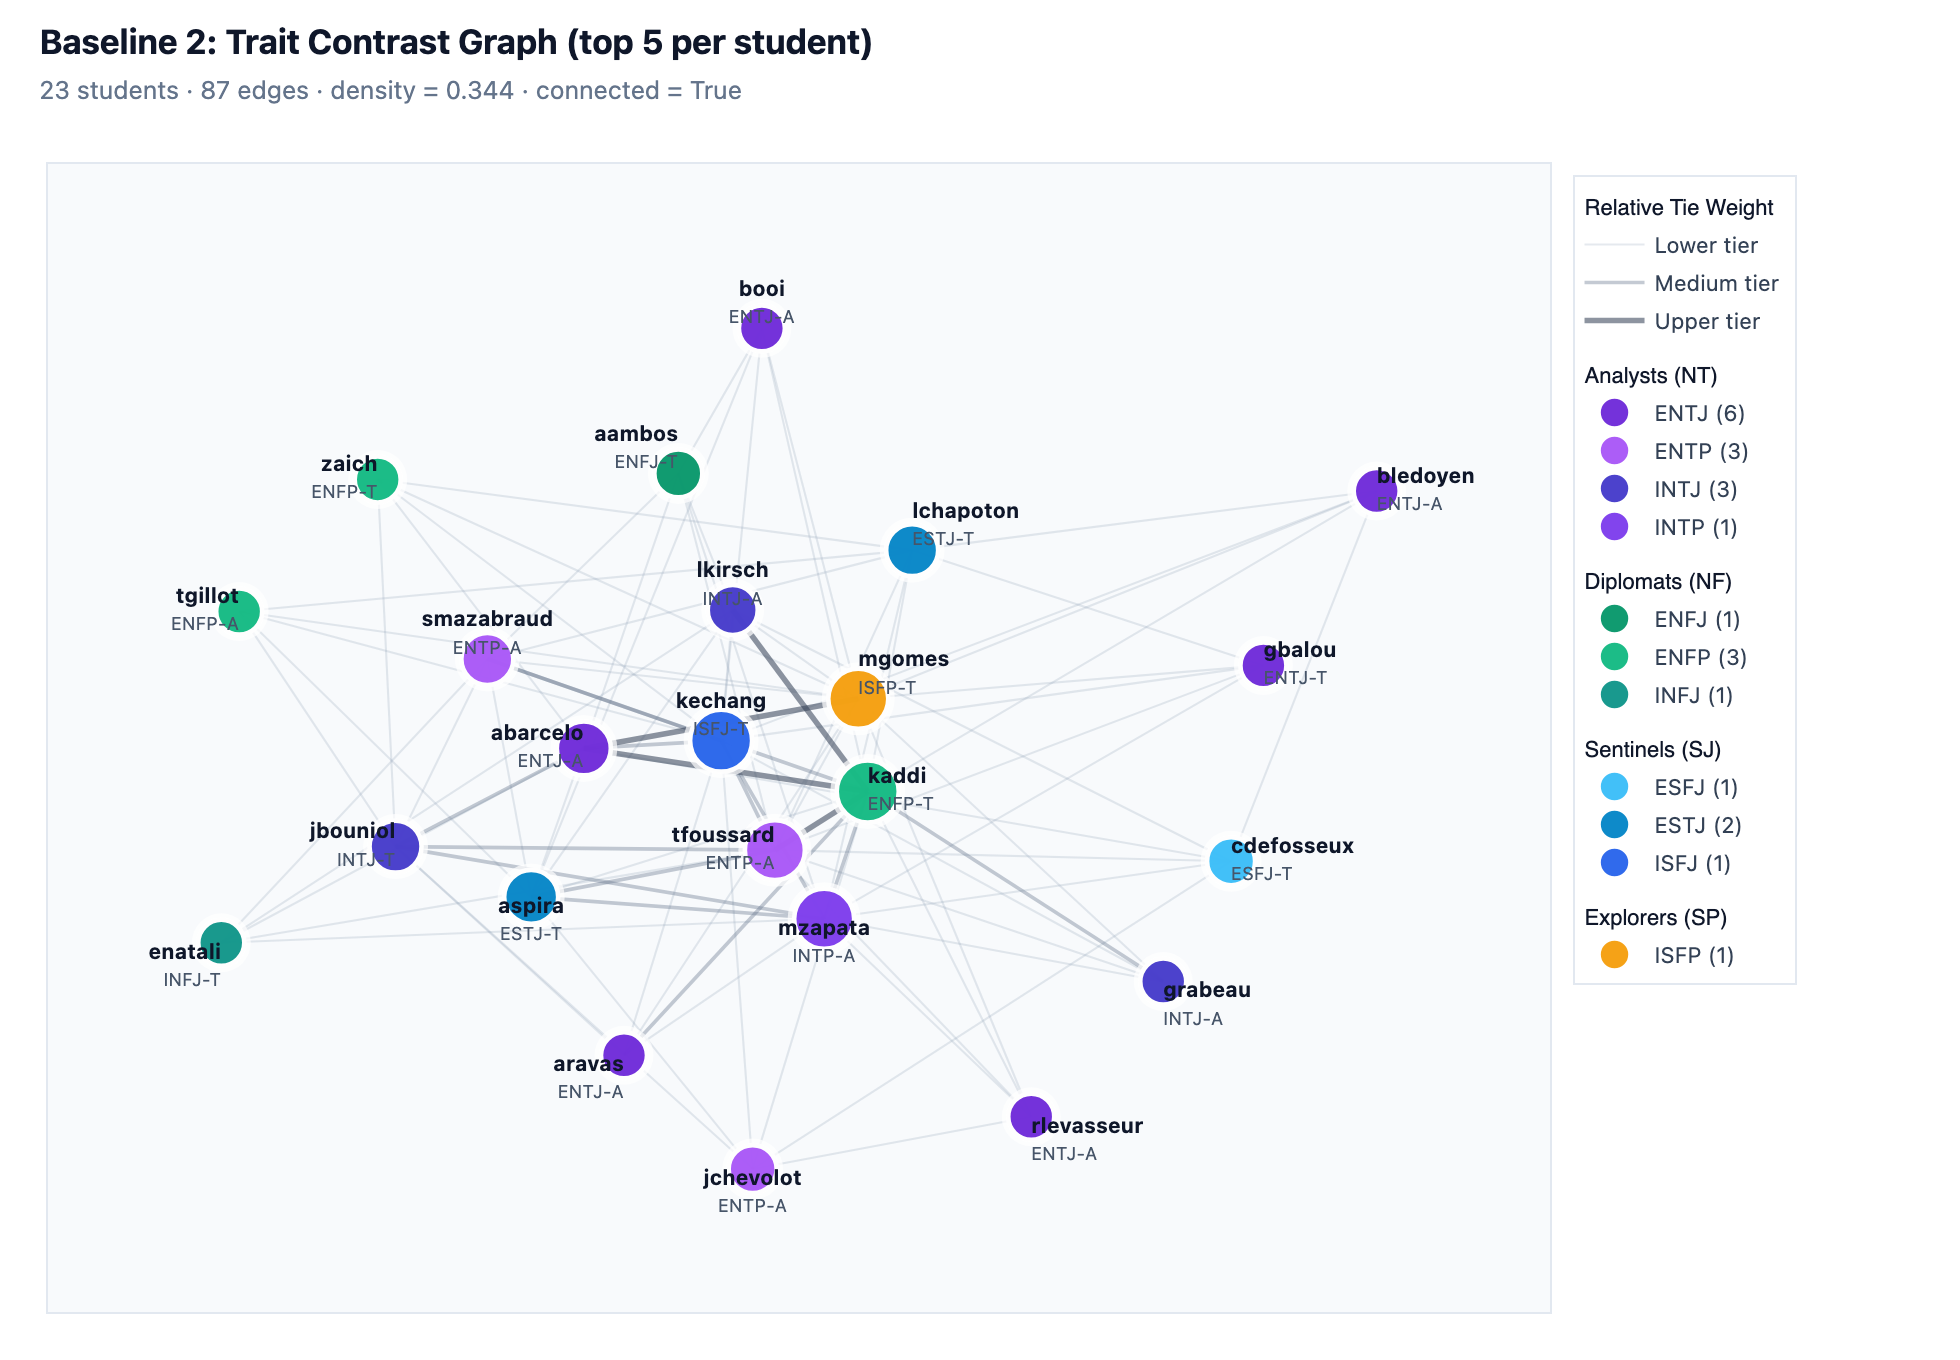

In [3]:
G_contrast = G_base.copy()
top_k = 5
centered = df[traits].values - 0.5
contrast_scores = {}

for i in range(len(students)):
    for j in range(i + 1, len(students)):
        opposition = 4.0 * np.maximum(0.0, -(centered[i] * centered[j]))
        contrast_scores[(i, j)] = float(opposition.mean())

for i, u in enumerate(students):
    neighbors = [
        (students[j], contrast_scores[(min(i, j), max(i, j))])
        for j in range(len(students)) if i != j
    ]
    neighbors.sort(key=lambda x: x[1], reverse=True)
    for v, score in neighbors[:top_k]:
        G_contrast.add_edge(u, v, weight=score)

contrast_df = pd.DataFrame([
    {
        "Student A": u, "MBTI A": df.loc[u, "mbti"],
        "Student B": v, "MBTI B": df.loc[v, "mbti"],
        "Contrast (%)": round(d["weight"] * 100, 1),
    }
    for u, v, d in G_contrast.edges(data=True)
]).sort_values("Contrast (%)", ascending=False).reset_index(drop=True)

print(f"Contrast graph: {G_contrast.number_of_nodes()} nodes, {G_contrast.number_of_edges()} edges")
display(contrast_df.head(10))

pos_con = nx.spring_layout(G_contrast, seed=42, k=1.05, iterations=200)
plot_network(G_contrast, pos_con, f"Baseline 2: Trait Contrast Graph (top {top_k} per student)")

## 3. Work-Group Compatibility Graph

Pure similarity creates a very dense graph where almost everyone is linked, while pure opposition pairs profiles that may clash on organization and communication. 

To model realistic project teams, we define an ideal partner vector for each student across the 5 traits:
- **Energy (`E`)**: complementary (`1 - E`), balancing outspoken and quieter team members.
- **Mind (`N`) & Nature (`T`)**: aligned (`N`, `T`), so teammates process ideas and feedback in a compatible way.
- **Tactics (`J`) & Identity (`A`)**: averaged with `0.65` (`(x + 0.65) / 2`), slightly favoring structure and emotional steadiness under deadlines.

We average the normalized Euclidean distance in both directions to get a symmetric score, then build an undirected $k$-NN graph ($k = 4$).

Compatibility graph (4-NN): 23 nodes, 67 edges, density = 0.26, connected = True, degree range = [4, 10]


,Student A,Type A,Student B,Type B,Compatibility (%)
0,grabeau,INTJ-A,rlevasseur,ENTJ-A,93.8
1,aravas,ENTJ-A,grabeau,INTJ-A,92.5
2,aambos,ENFJ-T,enatali,INFJ-T,92.2
3,bledoyen,ENTJ-A,grabeau,INTJ-A,91.6
4,aspira,ESTJ-T,lchapoton,ESTJ-T,90.3
5,gbalou,ENTJ-T,grabeau,INTJ-A,89.3
6,booi,ENTJ-A,enatali,INFJ-T,89.2
7,bledoyen,ENTJ-A,booi,ENTJ-A,89.1
8,bledoyen,ENTJ-A,gbalou,ENTJ-T,89.1
9,cdefosseux,ESFJ-T,kechang,ISFJ-T,89.1


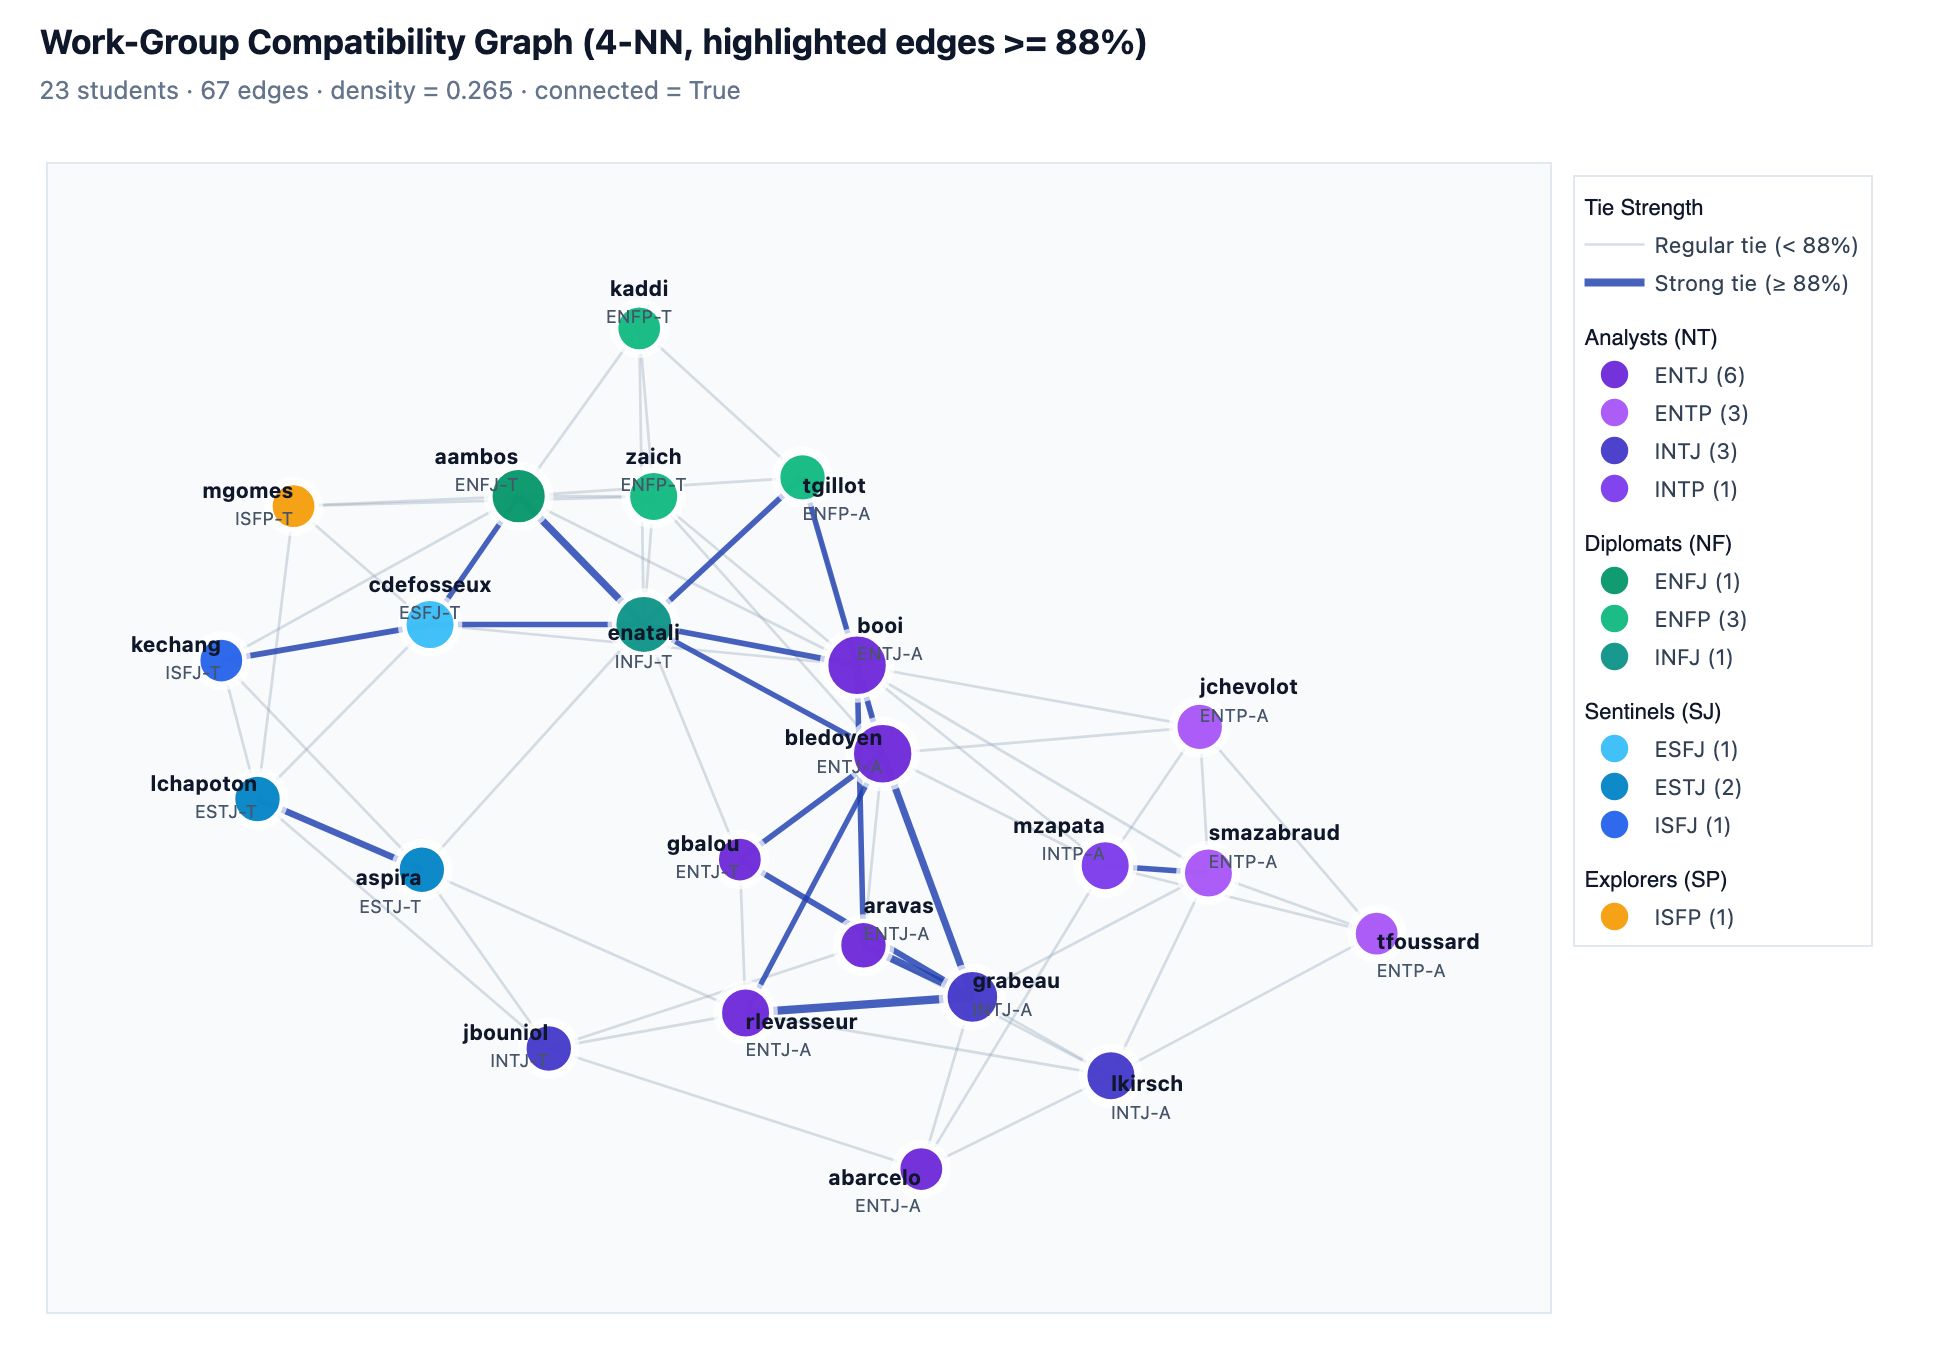

In [4]:
def ideal_partner(x, anchor=0.65):
    return np.array([
        1.0 - x[0],             # E: complementary energy
        x[1],                   # N: aligned intuition/sensing
        x[2],                   # T: aligned thinking/feeling
        0.5 * (x[3] + anchor),  # J: pulled toward structure
        0.5 * (x[4] + anchor),  # A: pulled toward calm stability
    ])


X = df[traits].values
X_ideal = np.array([ideal_partner(row) for row in X])
n = len(students)

compat_matrix = np.zeros((n, n))
compat_pairs = []

for i in range(n):
    for j in range(i + 1, n):
        u, v = students[i], students[j]
        d_ab = np.linalg.norm(X[j] - X_ideal[i]) / np.sqrt(len(traits))
        d_ba = np.linalg.norm(X[i] - X_ideal[j]) / np.sqrt(len(traits))
        score = float(1.0 - 0.5 * (d_ab + d_ba))

        compat_matrix[i, j] = compat_matrix[j, i] = score
        compat_pairs.append({
            "Student A": u, "Type A": f"{df.loc[u, 'mbti']}{df.loc[u, 'variant']}",
            "Student B": v, "Type B": f"{df.loc[v, 'mbti']}{df.loc[v, 'variant']}",
            "Compatibility (%)": round(score * 100, 1),
        })

G_compat = G_base.copy()
k_neighbors = 4
for i, u in enumerate(students):
    top_idx = [j for j in np.argsort(compat_matrix[i])[::-1] if j != i][:k_neighbors]
    for j in top_idx:
        G_compat.add_edge(u, students[j], weight=compat_matrix[i, j])

compat_df = pd.DataFrame(compat_pairs).sort_values("Compatibility (%)", ascending=False).reset_index(drop=True)
deg = dict(G_compat.degree())
print(
    f"Compatibility graph ({k_neighbors}-NN): {G_compat.number_of_nodes()} nodes, "
    f"{G_compat.number_of_edges()} edges, density = {nx.density(G_compat):.2f}, "
    f"connected = {nx.is_connected(G_compat)}, degree range = [{min(deg.values())}, {max(deg.values())}]"
)
display(compat_df.head(15))

pos_compat = nx.spring_layout(G_compat, seed=42, k=0.9, iterations=150, weight="weight")
plot_network(
    G_compat,
    pos_compat,
    f"Work-Group Compatibility Graph ({k_neighbors}-NN, highlighted edges >= 88%)",
    highlight_above=0.88,
)

## 4. Connectivity and Parameter Sensitivity

A graph is connected when every pair of students has a path between them. We first compare the three model graphs at their current settings, then vary the similarity cutoff, the number of contrast links retained per student, and the compatibility $k$-nearest-neighbor value. Every rebuilt graph keeps all students as nodes; for directed neighbor selections, an undirected edge is included if either student selects the other.

The component count and largest-component share show when a model fragments. Shortest-path distances between different components are undefined (effectively infinite), so a disconnected graph has no finite whole-graph diameter or radius. For later distance analysis, report metrics per component or explicitly restrict them to the largest component; for compatibility-weighted distances, use edge cost $d = 1 - w$ rather than treating compatibility itself as a distance.

In [5]:
def connectivity_summary(G, model, setting):
    components = sorted(nx.connected_components(G), key=len, reverse=True)
    largest_size = len(components[0]) if components else 0
    node_count = G.number_of_nodes()
    return {
        "Model": model,
        "Setting": setting,
        "Nodes": node_count,
        "Edges": G.number_of_edges(),
        "Density": round(nx.density(G), 3),
        "Connected": len(components) == 1,
        "Components": len(components),
        "Largest component": largest_size,
        "Largest component (%)": round(100 * largest_size / node_count, 1) if node_count else 0.0,
        "Isolates": nx.number_of_isolates(G),
        "Component sizes": [len(component) for component in components],
    }


baseline_connectivity = pd.DataFrame([
    connectivity_summary(G_sim, "Trait similarity", f"threshold >= {threshold:.2f}"),
    connectivity_summary(G_contrast, "Trait contrast", f"top {top_k} per student"),
    connectivity_summary(G_compat, "Compatibility", f"{k_neighbors}-NN"),
])
display(baseline_connectivity)

similarity_sweep = []
for cutoff in np.round(np.arange(0.60, 0.951, 0.05), 2):
    graph = G_base.copy()
    for i in range(len(students)):
        for j in range(i + 1, len(students)):
            similarity = float(1.0 - np.abs(df.loc[students[i], traits].values - df.loc[students[j], traits].values).mean())
            if similarity >= cutoff:
                graph.add_edge(students[i], students[j], weight=similarity)
    similarity_sweep.append(connectivity_summary(graph, "Trait similarity", f"threshold >= {cutoff:.2f}"))

contrast_sweep = []
compatibility_sweep = []
for k in range(1, len(students)):
    contrast_graph = G_base.copy()
    for i, student in enumerate(students):
        ranked = sorted(
            ((j, contrast_scores[(min(i, j), max(i, j))]) for j in range(len(students)) if j != i),
            key=lambda item: item[1],
            reverse=True,
        )
        for j, score in ranked[:k]:
            contrast_graph.add_edge(student, students[j], weight=score)
    contrast_sweep.append(connectivity_summary(contrast_graph, "Trait contrast", f"top {k} per student"))

    compatibility_graph = G_base.copy()
    for i, student in enumerate(students):
        ranked = sorted(
            (j for j in range(len(students)) if j != i),
            key=lambda j: compat_matrix[i, j],
            reverse=True,
        )
        for j in ranked[:k]:
            compatibility_graph.add_edge(student, students[j], weight=compat_matrix[i, j])
    compatibility_sweep.append(connectivity_summary(compatibility_graph, "Compatibility", f"{k}-NN"))

sweep_columns = ["Setting", "Edges", "Density", "Connected", "Components", "Largest component", "Largest component (%)", "Isolates"]
display(pd.DataFrame(similarity_sweep)[sweep_columns])
display(pd.DataFrame(contrast_sweep)[sweep_columns])
display(pd.DataFrame(compatibility_sweep)[sweep_columns])

,Model,Setting,Nodes,Edges,Density,Connected,Components,Largest component,Largest component (%),Isolates,Component sizes
0,Trait similarity,threshold >= 0.80,23,140,0.553,True,1,23,100.0,0,[23]
1,Trait contrast,top 5 per student,23,87,0.344,True,1,23,100.0,0,[23]
2,Compatibility,4-NN,23,67,0.265,True,1,23,100.0,0,[23]


,Setting,Edges,Density,Connected,Components,Largest component,Largest component (%),Isolates
0,threshold >= 0.60,249,0.984,True,1,23,100.0,0
1,threshold >= 0.65,241,0.953,True,1,23,100.0,0
2,threshold >= 0.70,223,0.881,True,1,23,100.0,0
3,threshold >= 0.75,194,0.767,True,1,23,100.0,0
4,threshold >= 0.80,140,0.553,True,1,23,100.0,0
5,threshold >= 0.85,70,0.277,False,3,21,91.3,2
6,threshold >= 0.90,19,0.075,False,9,10,43.5,5
7,threshold >= 0.95,0,0.000,False,23,1,4.3,23


,Setting,Edges,Density,Connected,Components,Largest component,Largest component (%),Isolates
0,top 1 per student,22,0.087,True,1,23,100.0,0
1,top 2 per student,41,0.162,True,1,23,100.0,0
2,top 3 per student,59,0.233,True,1,23,100.0,0
3,top 4 per student,74,0.292,True,1,23,100.0,0
4,top 5 per student,87,0.344,True,1,23,100.0,0
5,top 6 per student,102,0.403,True,1,23,100.0,0
6,top 7 per student,112,0.443,True,1,23,100.0,0
7,top 8 per student,125,0.494,True,1,23,100.0,0
8,top 9 per student,135,0.534,True,1,23,100.0,0
9,top 10 per student,146,0.577,True,1,23,100.0,0


,Setting,Edges,Density,Connected,Components,Largest component,Largest component (%),Isolates
0,1-NN,18,0.071,False,5,9,39.1,0
1,2-NN,37,0.146,True,1,23,100.0,0
2,3-NN,52,0.206,True,1,23,100.0,0
3,4-NN,67,0.265,True,1,23,100.0,0
4,5-NN,81,0.320,True,1,23,100.0,0
5,6-NN,96,0.379,True,1,23,100.0,0
6,7-NN,111,0.439,True,1,23,100.0,0
7,8-NN,124,0.490,True,1,23,100.0,0
8,9-NN,136,0.538,True,1,23,100.0,0
9,10-NN,150,0.593,True,1,23,100.0,0


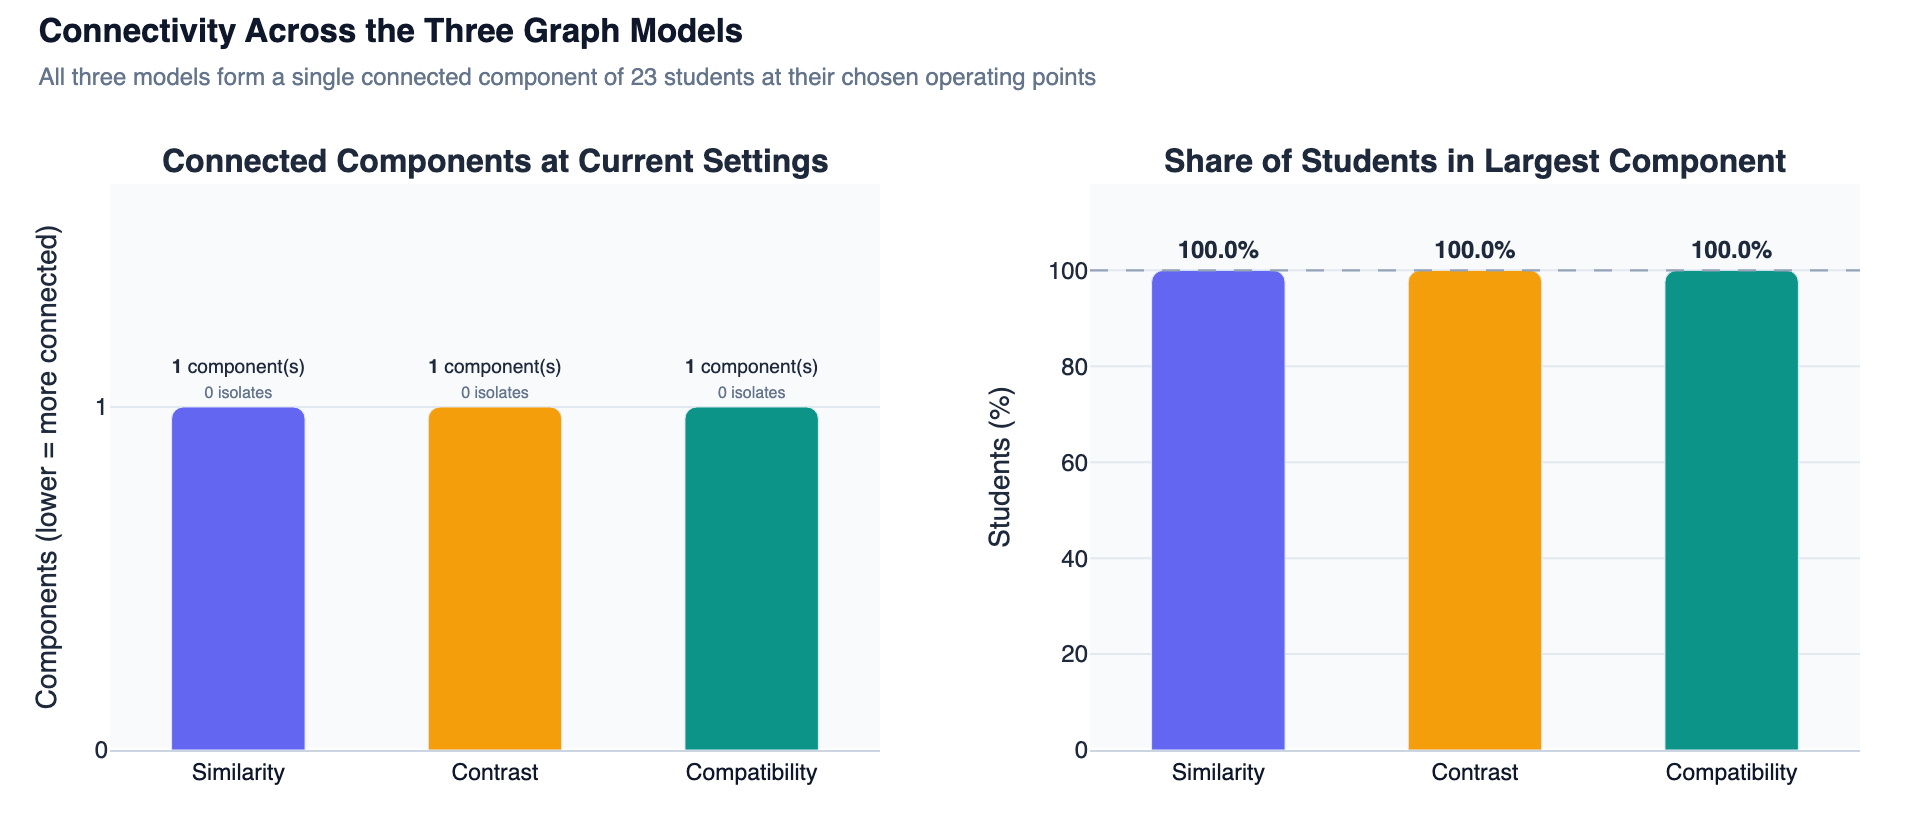

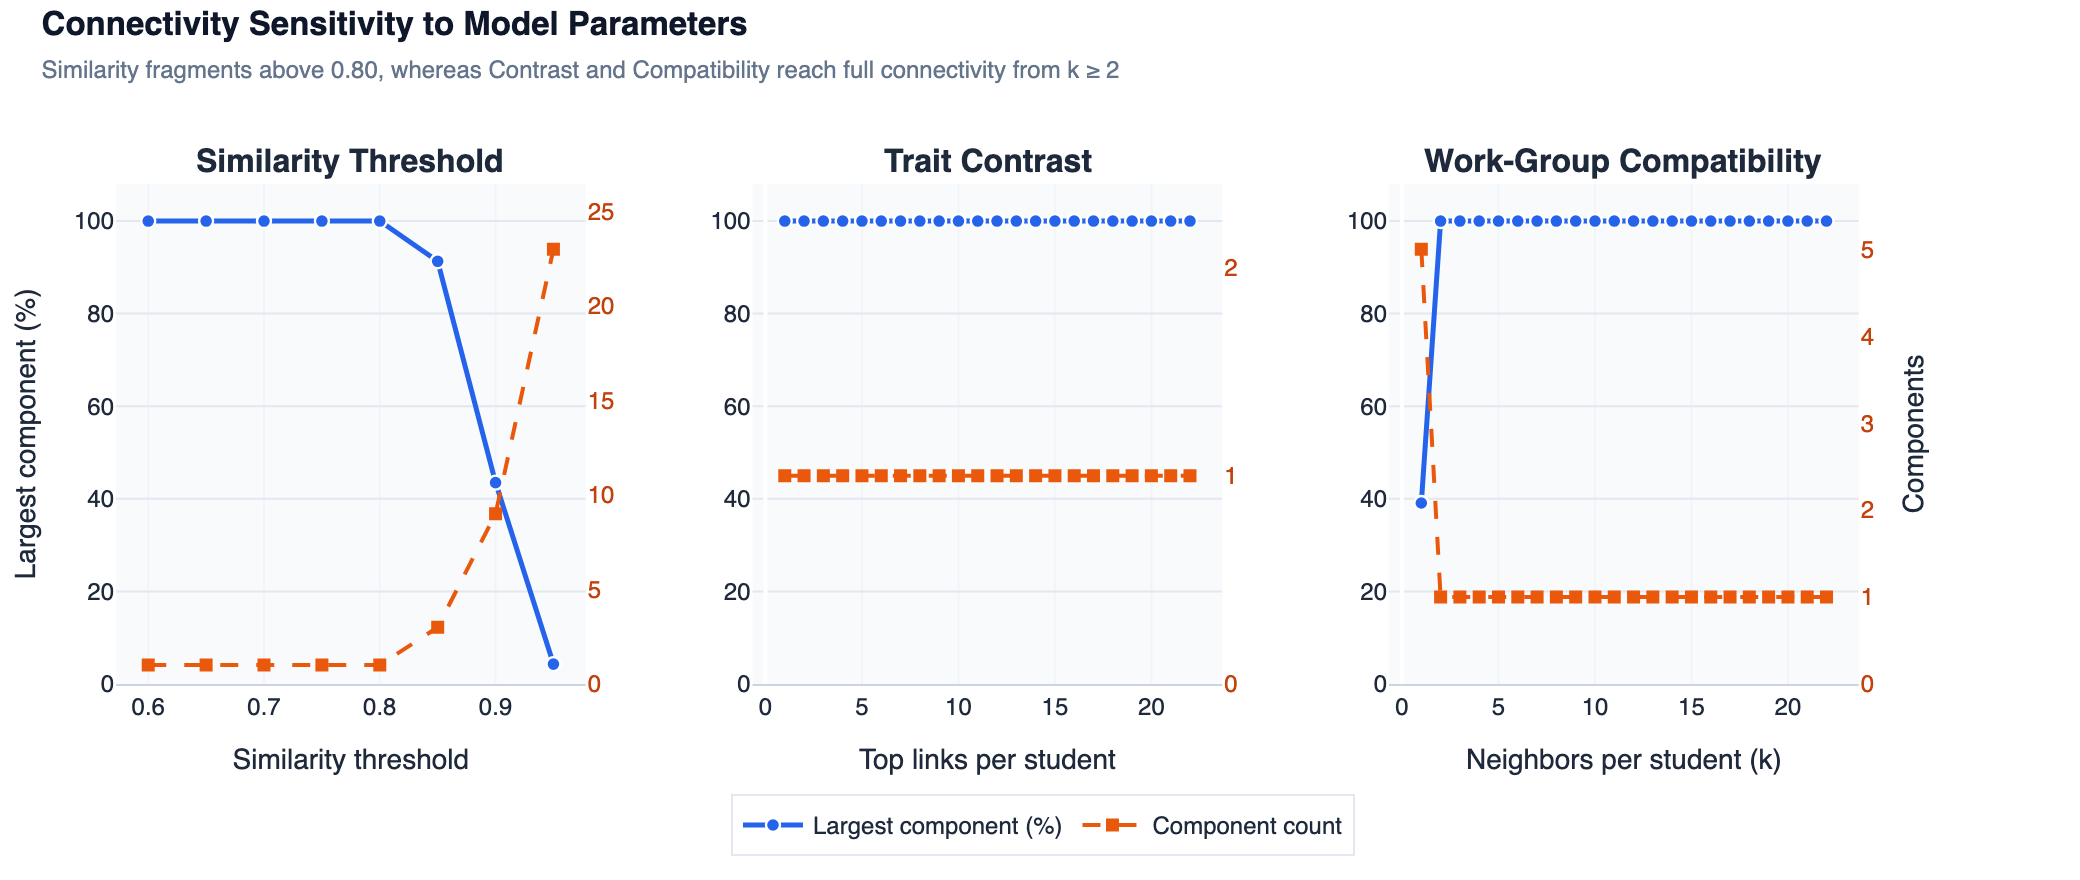

In [6]:
model_order = ["Trait similarity", "Trait contrast", "Work-group compatibility"]
model_short = ["Similarity", "Contrast", "Compatibility"]
model_colors = ["#6366F1", "#F59E0B", "#0D9488"]

# Compare the current graph settings by component structure and reachable share.
baseline_plot = (
    baseline_connectivity.set_index("Model")
    .rename(index={"Compatibility": "Work-group compatibility"})
    .reindex(model_order)
)

fig_conn_bar = make_subplots(
    rows=1,
    cols=2,
    subplot_titles=("<b>Connected Components at Current Settings</b>", "<b>Share of Students in Largest Component</b>"),
    horizontal_spacing=0.12,
)
fig_conn_bar.add_trace(
    go.Bar(
        x=model_short,
        y=baseline_plot["Components"],
        marker=dict(color=model_colors, cornerradius=6),
        width=0.52,
        text=[
            f"<b>{int(r['Components'])}</b> component(s)<br><span style='font-size:10px;color:#64748B'>{int(r['Isolates'])} isolates</span>"
            for _, r in baseline_plot.iterrows()
        ],
        textposition="outside",
        showlegend=False,
    ),
    row=1,
    col=1,
)
fig_conn_bar.add_trace(
    go.Bar(
        x=model_short,
        y=baseline_plot["Largest component (%)"],
        marker=dict(color=model_colors, cornerradius=6),
        width=0.52,
        text=[f"<b>{v:.1f}%</b>" for v in baseline_plot["Largest component (%)"]],
        textposition="outside",
        showlegend=False,
    ),
    row=1,
    col=2,
)
fig_conn_bar.add_hline(y=100, line_dash="dash", line_color="#94A3B8", line_width=1.2, row=1, col=2)
fig_conn_bar.update_yaxes(
    title_text="Components (lower = more connected)",
    range=[0, max(1.65, float(baseline_plot["Components"].max()) * 1.45)],
    dtick=1,
    gridcolor="#E2E8F0",
    row=1,
    col=1,
)
fig_conn_bar.update_yaxes(title_text="Students (%)", range=[0, 118], gridcolor="#E2E8F0", row=1, col=2)
fig_conn_bar.update_xaxes(linecolor="#CBD5E1", tickfont=dict(size=11.5, color="#0F172A"))
fig_conn_bar.update_layout(
    title=dict(
        text="<b>Connectivity Across the Three Graph Models</b><br><span style='font-size:12px;color:#64748B;font-weight:400'>All three models form a single connected component of 23 students at their chosen operating points</span>",
        x=0.02,
        y=0.95,
        font=dict(size=16.5, color="#0F172A", family="Inter, -apple-system, sans-serif"),
    ),
    width=960,
    height=420,
    paper_bgcolor="#FFFFFF",
    plot_bgcolor="#F8FAFC",
    font=dict(family="Inter, -apple-system, sans-serif", color="#1E293B"),
    margin=dict(l=55, r=30, t=92, b=45),
)
fig_conn_bar.show()

# Show how the largest component and total component count change as each model is tuned.
sweep_specs = [
    (similarity_sweep, "Similarity threshold", 5),
    (contrast_sweep, "Top links per student", 1),
    (compatibility_sweep, "Neighbors per student (k)", 1),
]
fig_sweep = make_subplots(
    rows=1,
    cols=3,
    specs=[[{"secondary_y": True}, {"secondary_y": True}, {"secondary_y": True}]],
    subplot_titles=("<b>Similarity Threshold</b>", "<b>Trait Contrast</b>", "<b>Work-Group Compatibility</b>"),
    horizontal_spacing=0.09,
)
for col_idx, (sweep, x_label, comp_dtick) in enumerate(sweep_specs, start=1):
    sweep_plot = pd.DataFrame(sweep).copy()
    sweep_plot["Parameter"] = sweep_plot["Setting"].str.extract(r"([0-9]+(?:\.[0-9]+)?)").astype(float)
    sweep_plot = sweep_plot.sort_values("Parameter")
    max_comp = float(sweep_plot["Components"].max())

    fig_sweep.add_trace(
        go.Scatter(
            x=sweep_plot["Parameter"],
            y=sweep_plot["Largest component (%)"],
            mode="lines+markers",
            name="Largest component (%)",
            line=dict(color="#2563EB", width=2.5),
            marker=dict(size=7, color="#2563EB", line=dict(width=1.2, color="#FFFFFF")),
            showlegend=(col_idx == 1),
        ),
        row=1,
        col=col_idx,
        secondary_y=False,
    )
    fig_sweep.add_trace(
        go.Scatter(
            x=sweep_plot["Parameter"],
            y=sweep_plot["Components"],
            mode="lines+markers",
            name="Component count",
            line=dict(color="#EA580C", width=2.0, dash="dash"),
            marker=dict(size=6.5, symbol="square", color="#EA580C"),
            showlegend=(col_idx == 1),
        ),
        row=1,
        col=col_idx,
        secondary_y=True,
    )
    fig_sweep.update_xaxes(title_text=x_label, gridcolor="#F1F5F9", linecolor="#CBD5E1", row=1, col=col_idx)
    fig_sweep.update_yaxes(
        title_text="Largest component (%)" if col_idx == 1 else "",
        range=[0, 108],
        gridcolor="#E2E8F0",
        secondary_y=False,
        row=1,
        col=col_idx,
    )
    fig_sweep.update_yaxes(
        title_text="Components" if col_idx == 3 else "",
        range=[0, max(2.4, max_comp * 1.15)],
        dtick=comp_dtick,
        tickfont=dict(color="#C2410C"),
        showgrid=False,
        secondary_y=True,
        row=1,
        col=col_idx,
    )

fig_sweep.update_layout(
    title=dict(
        text="<b>Connectivity Sensitivity to Model Parameters</b><br><span style='font-size:12px;color:#64748B;font-weight:400'>Similarity fragments above 0.80, whereas Contrast and Compatibility reach full connectivity from k ≥ 2</span>",
        x=0.02,
        y=0.96,
        font=dict(size=16.5, color="#0F172A", family="Inter, -apple-system, sans-serif"),
    ),
    width=1040,
    height=440,
    paper_bgcolor="#FFFFFF",
    plot_bgcolor="#F8FAFC",
    font=dict(family="Inter, -apple-system, sans-serif", color="#1E293B"),
    legend=dict(orientation="h", x=0.5, y=-0.22, xanchor="center", bgcolor="rgba(255,255,255,0.92)", bordercolor="#E2E8F0", borderwidth=1),
    margin=dict(l=55, r=55, t=92, b=82),
)
fig_sweep.show()

## 5. Distance Measures

Distance measures summarize how many steps, or how much cumulative edge cost, separates students in each graph. The **unweighted diameter** is the longest shortest-path distance in hops; the **unweighted radius** is the smallest, over students, of their farthest hop distance. These show worst-case reach and how centrally located the best-positioned student is.

For weighted distances, the edge `weight` represents tie strength, not cost. Convert each weight `w` to a cost `d = 1 - w`, then sum costs along a path and choose the least-cost path. This makes stronger ties cheaper to traverse. It is a modeling assumption for all three graphs; in particular, the contrast graph's strength means degree of contrast, not trait similarity.

A disconnected graph has no path between components, so its whole-graph diameter and radius are undefined. We report both metrics separately for every connected component; a singleton component therefore has diameter and radius 0. Comparisons across component rows should account for their different sizes.

In [7]:
def distance_metrics_by_component(G, model):
    components = sorted(nx.connected_components(G), key=len, reverse=True)
    rows = []

    for component_number, nodes in enumerate(components, start=1):
        component = G.subgraph(nodes).copy()
        weighted_component = component.copy()

        for _, _, attrs in weighted_component.edges(data=True):
            if "weight" not in attrs:
                raise ValueError(f"{model} has an edge without a strength weight")
            strength = float(attrs["weight"])
            if not np.isfinite(strength) or not 0.0 <= strength <= 1.0:
                raise ValueError(f"{model} edge strengths must be finite values in [0, 1]")
            attrs["distance"] = 1.0 - strength

        weighted_shortest_paths = dict(
            nx.all_pairs_dijkstra_path_length(weighted_component, weight="distance")
        )
        weighted_eccentricities = {
            node: max(distances.values())
            for node, distances in weighted_shortest_paths.items()
        }

        rows.append({
            "Model": model,
            "Graph connected": len(components) == 1,
            "Component": component_number,
            "Component nodes": component.number_of_nodes(),
            "Component edges": component.number_of_edges(),
            "Diameter (hops)": nx.diameter(component),
            "Radius (hops)": nx.radius(component),
            "Weighted diameter (sum of 1 - w)": round(max(weighted_eccentricities.values()), 3),
            "Weighted radius (sum of 1 - w)": round(min(weighted_eccentricities.values()), 3),
        })

    return rows


distance_results = pd.DataFrame([
    row
    for model, graph in [
        ("Trait similarity", G_sim),
        ("Trait contrast", G_contrast),
        ("Work-group compatibility", G_compat),
    ]
    for row in distance_metrics_by_component(graph, model)
])
display(distance_results)

,Model,Graph connected,Component,Component nodes,Component edges,Diameter (hops),Radius (hops),Weighted diameter (sum of 1 - w),Weighted radius (sum of 1 - w)
0,Trait similarity,True,1,23,140,3,2,0.522,0.278
1,Trait contrast,True,1,23,87,3,2,2.705,1.746
2,Work-group compatibility,True,1,23,67,4,2,0.644,0.358


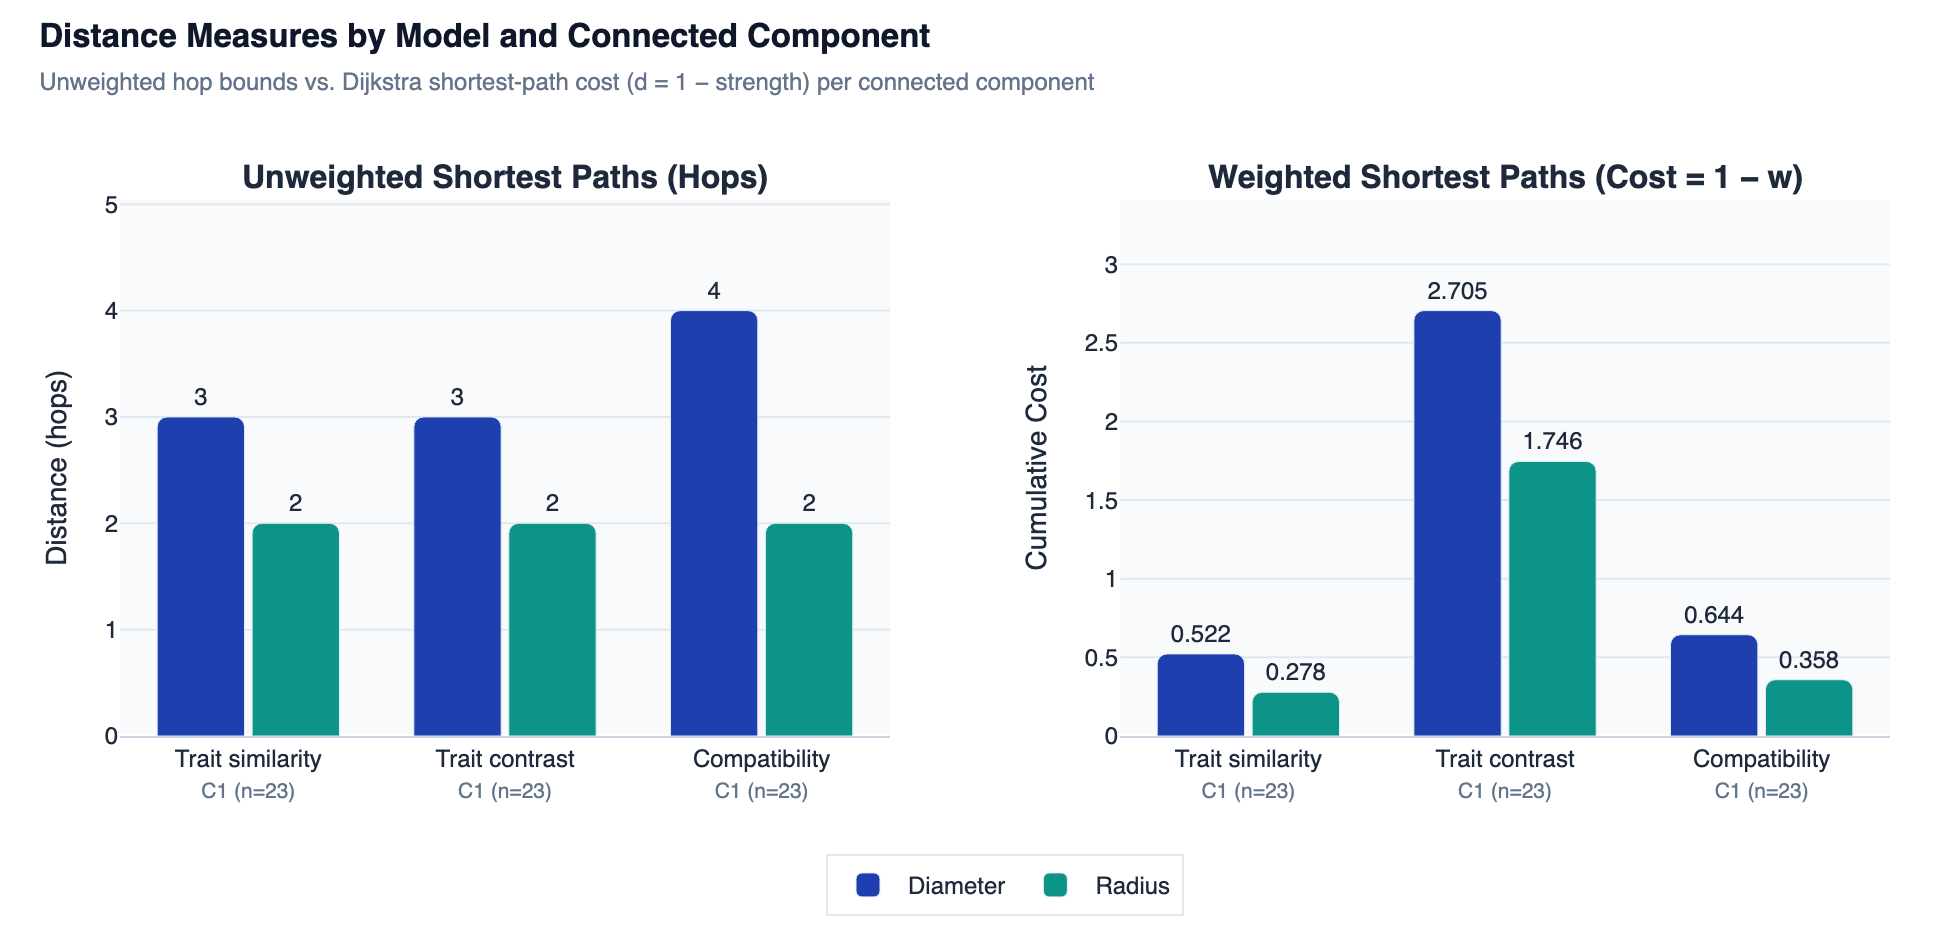

In [8]:
# Compare hop distances and strength-derived costs for every connected component.
distance_plot = distance_results.copy()
distance_plot["Component label"] = distance_plot.apply(
    lambda row: (
        f"{row['Model'].replace('Work-group ', '').capitalize()}"
        f"<br><span style='font-size:10.5px;color:#64748B'>C{int(row['Component'])} (n={int(row['Component nodes'])})</span>"
    ),
    axis=1,
)

fig_dist = make_subplots(
    rows=1,
    cols=2,
    subplot_titles=("<b>Unweighted Shortest Paths (Hops)</b>", "<b>Weighted Shortest Paths (Cost = 1 − w)</b>"),
    horizontal_spacing=0.13,
)
for col_idx, (d_col, r_col, fmt) in enumerate(
    [
        ("Diameter (hops)", "Radius (hops)", "{:.0f}"),
        ("Weighted diameter (sum of 1 - w)", "Weighted radius (sum of 1 - w)", "{:.3f}"),
    ],
    start=1,
):
    fig_dist.add_trace(
        go.Bar(
            x=distance_plot["Component label"],
            y=distance_plot[d_col],
            name="Diameter",
            marker=dict(color="#1E40AF", cornerradius=5),
            text=[fmt.format(v) for v in distance_plot[d_col]],
            textposition="outside",
            showlegend=(col_idx == 1),
        ),
        row=1,
        col=col_idx,
    )
    fig_dist.add_trace(
        go.Bar(
            x=distance_plot["Component label"],
            y=distance_plot[r_col],
            name="Radius",
            marker=dict(color="#0D9488", cornerradius=5),
            text=[fmt.format(v) for v in distance_plot[r_col]],
            textposition="outside",
            showlegend=(col_idx == 1),
        ),
        row=1,
        col=col_idx,
    )
    fig_dist.update_yaxes(
        title_text="Distance (hops)" if col_idx == 1 else "Cumulative Cost",
        range=[0, float(distance_plot[d_col].max()) * 1.26],
        gridcolor="#E2E8F0",
        row=1,
        col=col_idx,
    )
    fig_dist.update_xaxes(
        tickangle=0,
        linecolor="#CBD5E1",
        row=1,
        col=col_idx,
    )

fig_dist.update_layout(
    barmode="group",
    bargap=0.26,
    bargroupgap=0.08,
    title=dict(
        text="<b>Distance Measures by Model and Connected Component</b><br><span style='font-size:12px;color:#64748B;font-weight:400'>Unweighted hop bounds vs. Dijkstra shortest-path cost (d = 1 − strength) per connected component</span>",
        x=0.02,
        y=0.95,
        font=dict(size=16.5, color="#0F172A", family="Inter, -apple-system, sans-serif"),
    ),
    width=980,
    height=470,
    paper_bgcolor="#FFFFFF",
    plot_bgcolor="#F8FAFC",
    font=dict(family="Inter, -apple-system, sans-serif", color="#1E293B"),
    legend=dict(
        orientation="h",
        x=0.5,
        xanchor="center",
        y=-0.22,
        yanchor="top",
        bgcolor="rgba(255,255,255,0.95)",
        bordercolor="#E2E8F0",
        borderwidth=1,
    ),
    margin=dict(l=60, r=35, t=100, b=95),
)
fig_dist.show()

## 6. Centrality Measures

Centrality describes a student's structural position in the network, not their personality or real-world importance. We compute each measure for all three graph models so that their different notions of a tie (similarity, contrast, or work compatibility) can be examined separately. Interpret values across models with those different edge meanings in mind.

- **Degree** counts immediate connections; **degree centrality** normalizes that count by graph size. In the symmetrized k-nearest-neighbor graph, a student may have more than `k` neighbors because other students can select them.
- **Strength** sums incident edge weights. It distinguishes many links from strong links, and its meaning follows each model's definition of edge weight.
- **Betweenness** measures how often a student lies on shortest paths between others. We use unweighted (hop-based) paths to identify topological bridges without inventing a conversion from tie strength to distance.
- **Closeness** summarizes hop distance to reachable students. NetworkX's Wasserman-Faust adjustment reduces scores for students who can reach only a small component, so disconnected graphs are handled explicitly.
- **Eigenvector centrality** rewards links to well-connected students. We calculate it separately within each connected component (using edge strength), since scores from different components are not directly comparable. A singleton component receives a score of 1 by convention.

The full table shows scores in each model; the final table highlights the five highest scores per measure in the work-group compatibility graph. Student identifiers match those used in the earlier tables.

In [9]:
graph_models = [
    ("Trait similarity", G_sim),
    ("Trait contrast", G_contrast),
    ("Work-group compatibility", G_compat),
]
centrality_rows = []
for model, graph in graph_models:
    degree = dict(graph.degree())
    degree_centrality = nx.degree_centrality(graph)
    strength = dict(graph.degree(weight="weight"))
    betweenness = nx.betweenness_centrality(graph, normalized=True)
    closeness = nx.closeness_centrality(graph, wf_improved=True)

    eigenvector = {}
    component_numbers = {}
    components = sorted(nx.connected_components(graph), key=len, reverse=True)
    for component_number, nodes in enumerate(components, start=1):
        component_graph = graph.subgraph(nodes)
        component_numbers.update({node: component_number for node in nodes})
        if len(nodes) == 1:
            eigenvector.update({node: 1.0 for node in nodes})
        else:
            eigenvector.update(nx.eigenvector_centrality(component_graph, max_iter=1000, weight="weight"))

    for node in graph:
        centrality_rows.append({
            "Model": model,
            "Student": node,
            "MBTI": f"{df.loc[node, 'mbti']}{df.loc[node, 'variant']}",
            "Component": component_numbers[node],
            "Degree": degree[node],
            "Degree centrality": degree_centrality[node],
            "Strength": strength[node],
            "Betweenness": betweenness[node],
            "Closeness": closeness[node],
            "Eigenvector": eigenvector[node],
        })

centrality_results = pd.DataFrame(centrality_rows)
display(centrality_results.sort_values(["Model", "Betweenness"], ascending=[True, False]).reset_index(drop=True))

compatibility_centrality = centrality_results[
    centrality_results["Model"] == "Work-group compatibility"
]
top_centrality_rows = []
for measure in ["Degree", "Strength", "Betweenness", "Closeness", "Eigenvector"]:
    top_rows = compatibility_centrality.nlargest(5, measure)[["Student", "MBTI", measure]].rename(
        columns={measure: "Score"}
    )
    top_rows.insert(0, "Measure", measure)
    top_centrality_rows.append(top_rows)
top_compatibility_centrality = pd.concat(top_centrality_rows, ignore_index=True)
display(top_compatibility_centrality)

,Model,Student,MBTI,Component,Degree,Degree centrality,Strength,Betweenness,Closeness,Eigenvector
0,Trait contrast,kechang,ISFJ-T,1,13,0.590909,1.000640,0.105786,0.709677,0.273887
1,Trait contrast,mgomes,ISFP-T,1,12,0.545455,0.992080,0.098747,0.687500,0.247980
2,Trait contrast,kaddi,ENFP-T,1,13,0.590909,1.627840,0.096482,0.709677,0.460342
3,Trait contrast,mzapata,INTP-A,1,12,0.545455,0.924160,0.092829,0.687500,0.252537
4,Trait contrast,tfoussard,ENTP-A,1,12,0.545455,1.173680,0.079465,0.687500,0.342124
...,...,...,...,...,...,...,...,...,...,...
64,Work-group compatibility,mgomes,ISFP-T,1,4,0.181818,3.346564,0.011224,0.423077,0.124333
65,Work-group compatibility,gbalou,ENTJ-T,1,4,0.181818,3.485501,0.011018,0.500000,0.169677
66,Work-group compatibility,kechang,ISFJ-T,1,4,0.181818,3.477962,0.009173,0.431373,0.111351
67,Work-group compatibility,tfoussard,ENTP-A,1,4,0.181818,3.266018,0.003608,0.392857,0.104570


,Measure,Student,MBTI,Score
0,Degree,bledoyen,ENTJ-A,10.000000
1,Degree,booi,ENTJ-A,10.000000
2,Degree,enatali,INFJ-T,9.000000
3,Degree,aambos,ENFJ-T,8.000000
4,Degree,grabeau,INTJ-A,7.000000
5,Strength,bledoyen,ENTJ-A,8.747916
6,Strength,booi,ENTJ-A,8.703839
7,Strength,enatali,INFJ-T,7.845882
8,Strength,aambos,ENFJ-T,6.847955
9,Strength,grabeau,INTJ-A,6.140595


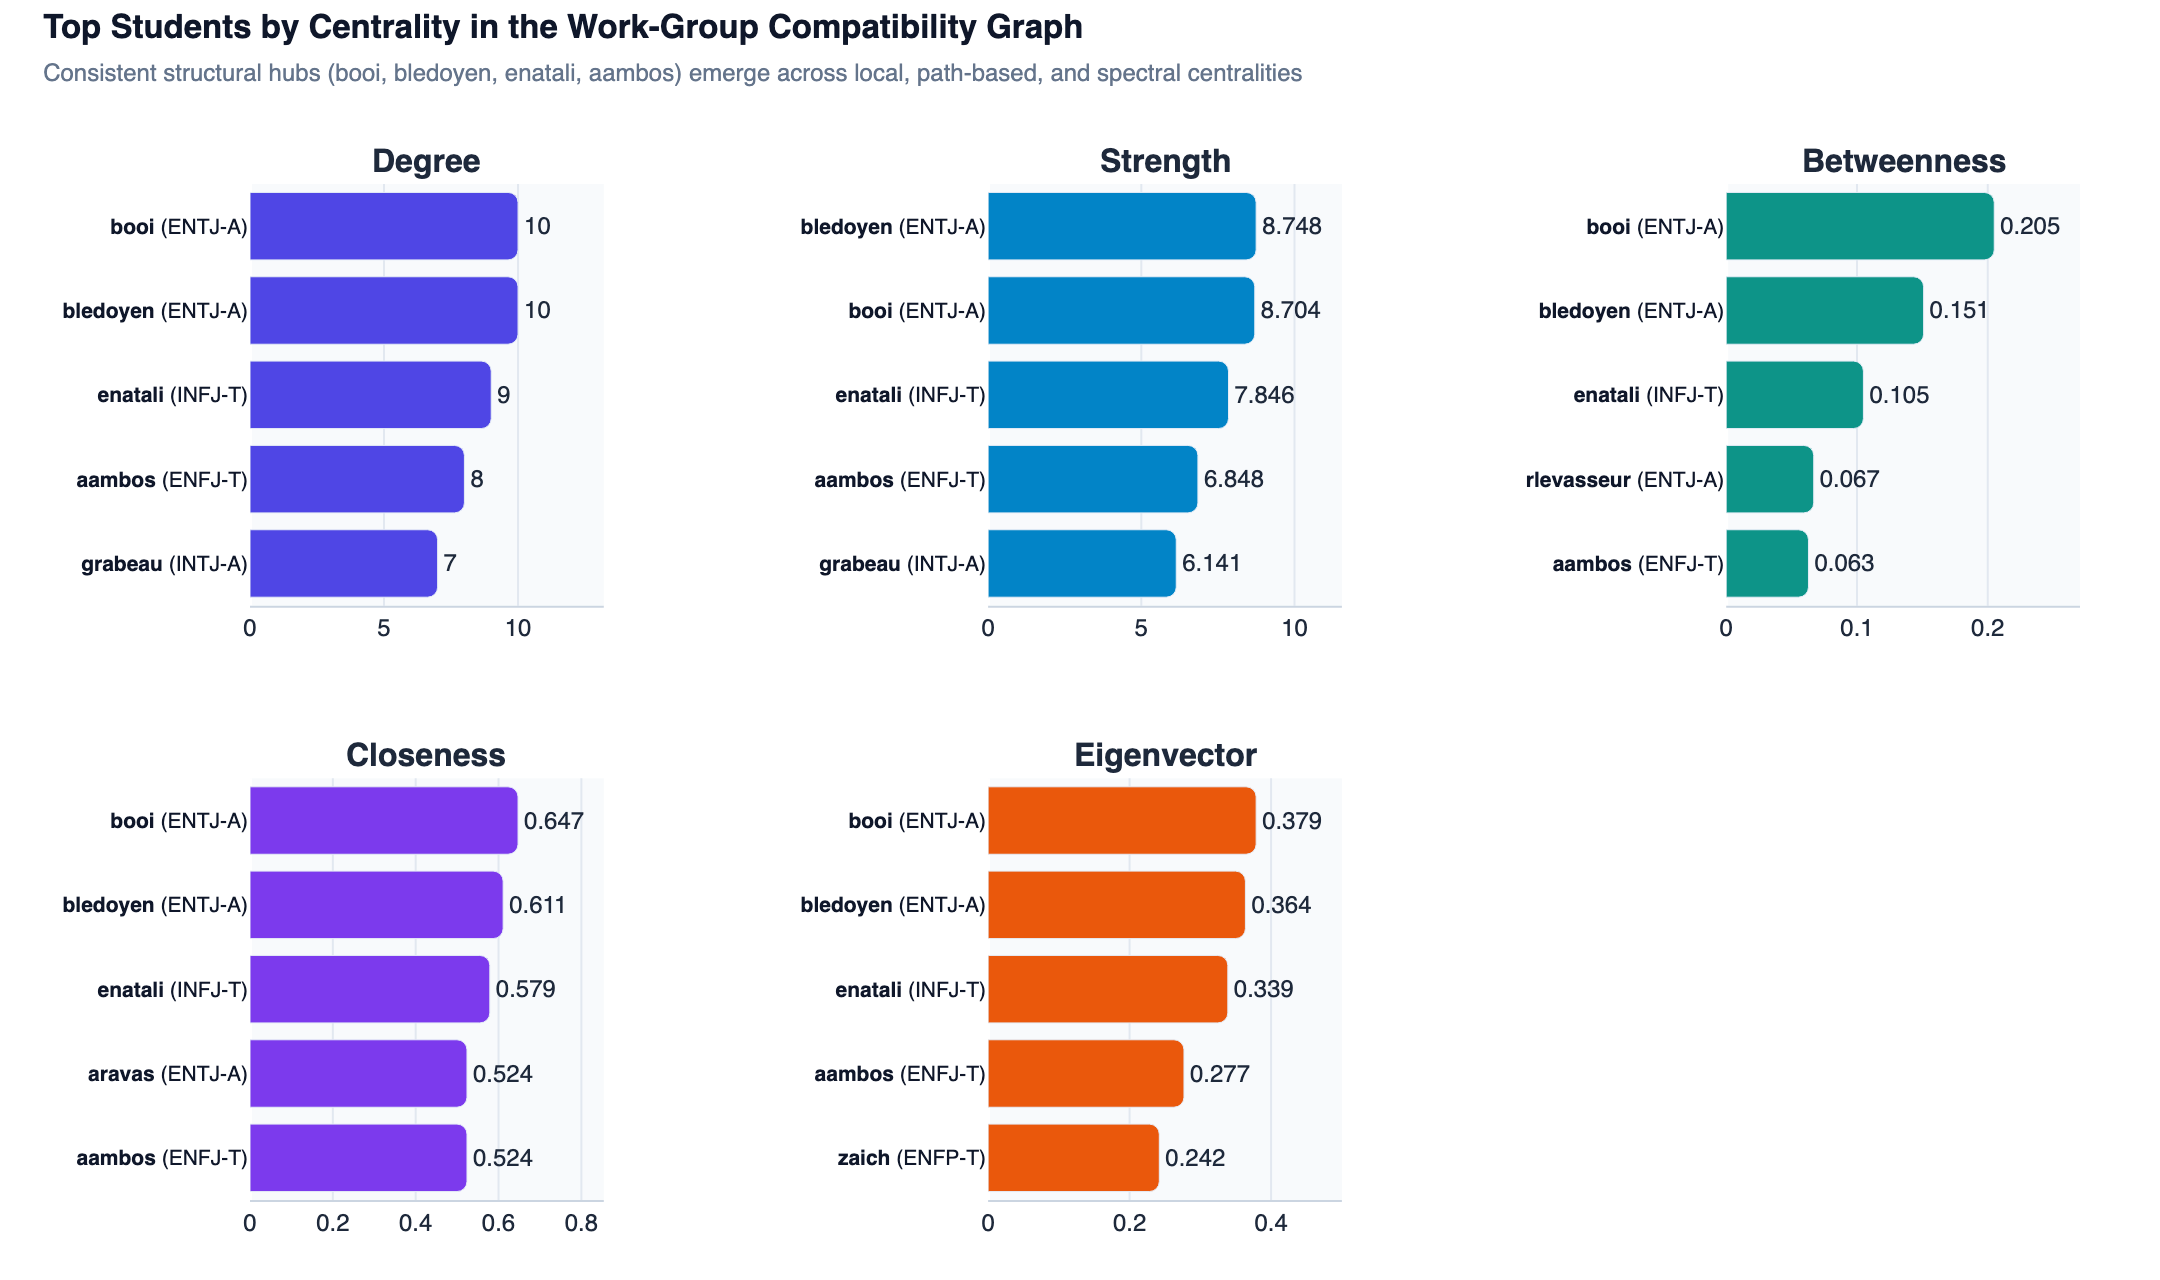

In [10]:
# Each centrality measure gets its own panel and scale; labels include MBTI type.
centrality_measures = ["Degree", "Strength", "Betweenness", "Closeness", "Eigenvector"]
measure_colors = ["#4F46E5", "#0284C7", "#0D9488", "#7C3AED", "#EA580C"]

fig_cent = make_subplots(
    rows=2,
    cols=3,
    subplot_titles=[f"<b>{m}</b>" for m in centrality_measures] + [""],
    horizontal_spacing=0.21,
    vertical_spacing=0.17,
)
for idx, (measure, mcol) in enumerate(zip(centrality_measures, measure_colors)):
    r_idx, c_idx = divmod(idx, 3)
    top_students = compatibility_centrality.nlargest(5, measure).sort_values(measure)
    labels = [f"<b>{row.Student}</b> ({row.MBTI})" for row in top_students.itertuples()]
    fmt_str = "{:.0f}" if measure == "Degree" else "{:.3f}"
    fig_cent.add_trace(
        go.Bar(
            x=top_students[measure],
            y=labels,
            orientation="h",
            marker=dict(color=mcol, cornerradius=5),
            text=[fmt_str.format(v) for v in top_students[measure]],
            textposition="outside",
            showlegend=False,
        ),
        row=r_idx + 1,
        col=c_idx + 1,
    )
    fig_cent.update_xaxes(
        range=[0, float(top_students[measure].max()) * 1.32],
        gridcolor="#E2E8F0",
        linecolor="#CBD5E1",
        row=r_idx + 1,
        col=c_idx + 1,
    )
    fig_cent.update_yaxes(tickfont=dict(size=10.5, color="#0F172A"), row=r_idx + 1, col=c_idx + 1)

fig_cent.update_layout(
    title=dict(
        text="<b>Top Students by Centrality in the Work-Group Compatibility Graph</b><br><span style='font-size:12px;color:#64748B;font-weight:400'>Consistent structural hubs (booi, bledoyen, enatali, aambos) emerge across local, path-based, and spectral centralities</span>",
        x=0.02,
        y=0.97,
        font=dict(size=16.5, color="#0F172A", family="Inter, -apple-system, sans-serif"),
    ),
    width=1080,
    height=640,
    paper_bgcolor="#FFFFFF",
    plot_bgcolor="#F8FAFC",
    font=dict(family="Inter, -apple-system, sans-serif", color="#1E293B"),
    margin=dict(l=125, r=40, t=92, b=40),
)
fig_cent.show()

## 7. Community Structure and Modularity Analysis

While centrality captures individual structural positions, **community detection** identifies meso-scale clusters of students who are more densely and strongly connected to each other than to the rest of the class. We apply the **Louvain modularity optimization algorithm** (`nx.community.louvain_communities`, `seed=42`) using edge weights on all three graph models and evaluate partition quality through weighted modularity $Q \in [-0.5, 1]$:

$$Q = \frac{1}{2m} \sum_{u, v} \left[ w_{uv} - \frac{s_u s_v}{2m} \right] \delta(c_u, c_v)$$

where $w_{uv}$ is edge weight, $s_u = \sum_v w_{uv}$ is node strength, $2m = \sum_{u,v} w_{uv}$, and $\delta(c_u, c_v) = 1$ if $u$ and $v$ belong to the same community.

Comparing modularity across the three models highlights a clear structural finding:
- **Trait similarity (`G_sim`)** yields low modularity ($Q = 0.128$, 3 clusters) because its high edge density (`0.553`) blurs boundaries between student groups.
- **Trait contrast (`G_contrast`)** exhibits near-zero modularity ($Q = 0.095$, 4 clusters) because edges purposefully link opposing personalities, producing a disassortative topology rather than cohesive clusters.
- **Work-group compatibility (`G_compat`)** achieves strong modularity (**$Q = 0.341$**, nearly $3\times$ higher than similarity) and partitions the 23 students into **4 balanced, interpretable team archetypes** ($n = 6, 6, 6, 5$):
  1. **C1 · Empathetic Diplomats ($n = 6$)**: `NF`-dominant profiles (`T = 44%`, `N = 69%`) anchored by key network bridges (`booi`, `enatali`, `aambos`).
  2. **C2 · Assertive Analysts ($n = 6$)**: exclusively `-A` profiles (`A = 82%`, `T = 82%`) with adaptable `NT-P` problem-solving styles (`J = 44%`).
  3. **C3 · Structured Organizers ($n = 6$)**: grounded, methodical teammates (`J = 70%`, `N = 44%`, `E = 41%`) bringing execution reliability and attention to detail.
  4. **C4 · Strategic Drivers ($n = 5$)**: `NT-J` architects and commanders (`N = 71%`, `T = 68%`, `J = 69%`) concentrating the highest pairwise compatibility ties in the cohort.

In [11]:
from scipy.spatial import ConvexHull
from scipy.interpolate import splprep, splev

CLUSTER_PALETTE = [
    ("#0D9488", "rgba(13, 148, 136, 0.11)", "rgba(13, 148, 136, 0.45)", "C1 · Empathetic Diplomats"),
    ("#7C3AED", "rgba(124, 58, 237, 0.11)", "rgba(124, 58, 237, 0.45)", "C2 · Assertive Analysts"),
    ("#0284C7", "rgba(2, 132, 199, 0.11)", "rgba(2, 132, 199, 0.45)", "C3 · Structured Organizers"),
    ("#EA580C", "rgba(234, 88, 12, 0.11)", "rgba(234, 88, 12, 0.45)", "C4 · Strategic Drivers"),
]

modularity_comparison = []
partitions_by_model = {}

for model_name, graph in [
    ("Trait similarity", G_sim),
    ("Trait contrast", G_contrast),
    ("Work-group compatibility", G_compat),
]:
    comms = sorted(
        nx.community.louvain_communities(graph, weight="weight", seed=42),
        key=lambda c: (-len(c), sorted(c)[0]),
    )
    partitions_by_model[model_name] = comms
    mod_q = nx.community.modularity(graph, comms, weight="weight")
    intra_edges = sum(graph.subgraph(c).number_of_edges() for c in comms)
    total_edges = graph.number_of_edges()

    modularity_comparison.append({
        "Model": model_name,
        "Communities": len(comms),
        "Cluster sizes": [len(c) for c in comms],
        "Modularity (Q)": round(mod_q, 3),
        "Intra-cluster edges (%)": round(100.0 * intra_edges / total_edges, 1) if total_edges else 0.0,
    })

modularity_df = pd.DataFrame(modularity_comparison)
display(modularity_df)

compat_communities = partitions_by_model["Work-group compatibility"]
compat_modularity = nx.community.modularity(G_compat, compat_communities, weight="weight")
node_to_community = {}
cluster_summary_rows = []

for idx, comm in enumerate(compat_communities):
    members = sorted(comm)
    label = CLUSTER_PALETTE[idx][3]
    for m in members:
        node_to_community[m] = idx

    sub = G_compat.subgraph(members)
    sub_weights = [d["weight"] for _, _, d in sub.edges(data=True)]
    means = df.loc[members, traits].mean()

    cluster_summary_rows.append({
        "Community": label,
        "Size": len(members),
        "Internal edges": sub.number_of_edges(),
        "Internal density": round(nx.density(sub), 2),
        "Mean internal tie (%)": round(100.0 * float(np.mean(sub_weights)), 1) if sub_weights else 0.0,
        "Mean E (%)": round(100.0 * float(means["E"]), 1),
        "Mean N (%)": round(100.0 * float(means["N"]), 1),
        "Mean T (%)": round(100.0 * float(means["T"]), 1),
        "Mean J (%)": round(100.0 * float(means["J"]), 1),
        "Mean A (%)": round(100.0 * float(means["A"]), 1),
        "Members (MBTI)": ", ".join(f"{m} ({df.loc[m, 'mbti']}{df.loc[m, 'variant']})" for m in members),
    })

cluster_summary_df = pd.DataFrame(cluster_summary_rows)
display(cluster_summary_df)

,Model,Communities,Cluster sizes,Modularity (Q),Intra-cluster edges (%)
0,Trait similarity,3,"[9, 9, 5]",0.128,46.4
1,Trait contrast,4,"[8, 7, 5, 3]",0.095,41.4
2,Work-group compatibility,4,"[6, 6, 6, 5]",0.341,59.7


,Community,Size,Internal edges,Internal density,Mean internal tie (%),Mean E (%),Mean N (%),Mean T (%),Mean J (%),Mean A (%),Members (MBTI)
0,C1 · Empathetic Diplomats,6,13,0.87,84.3,58.3,69.3,43.8,48.5,42.7,"aambos (ENFJ-T), booi (ENTJ-A), enatali (INFJ-..."
1,C2 · Assertive Analysts,6,10,0.67,81.7,61.8,59.0,82.0,44.3,82.5,"abarcelo (ENTJ-A), jchevolot (ENTP-A), lkirsch..."
2,C3 · Structured Organizers,6,9,0.60,85.8,41.3,43.8,54.5,70.0,38.3,"aspira (ESTJ-T), cdefosseux (ESFJ-T), jbouniol..."
3,C4 · Strategic Drivers,5,8,0.80,89.5,57.4,71.2,68.4,68.6,57.8,"aravas (ENTJ-A), bledoyen (ENTJ-A), gbalou (EN..."


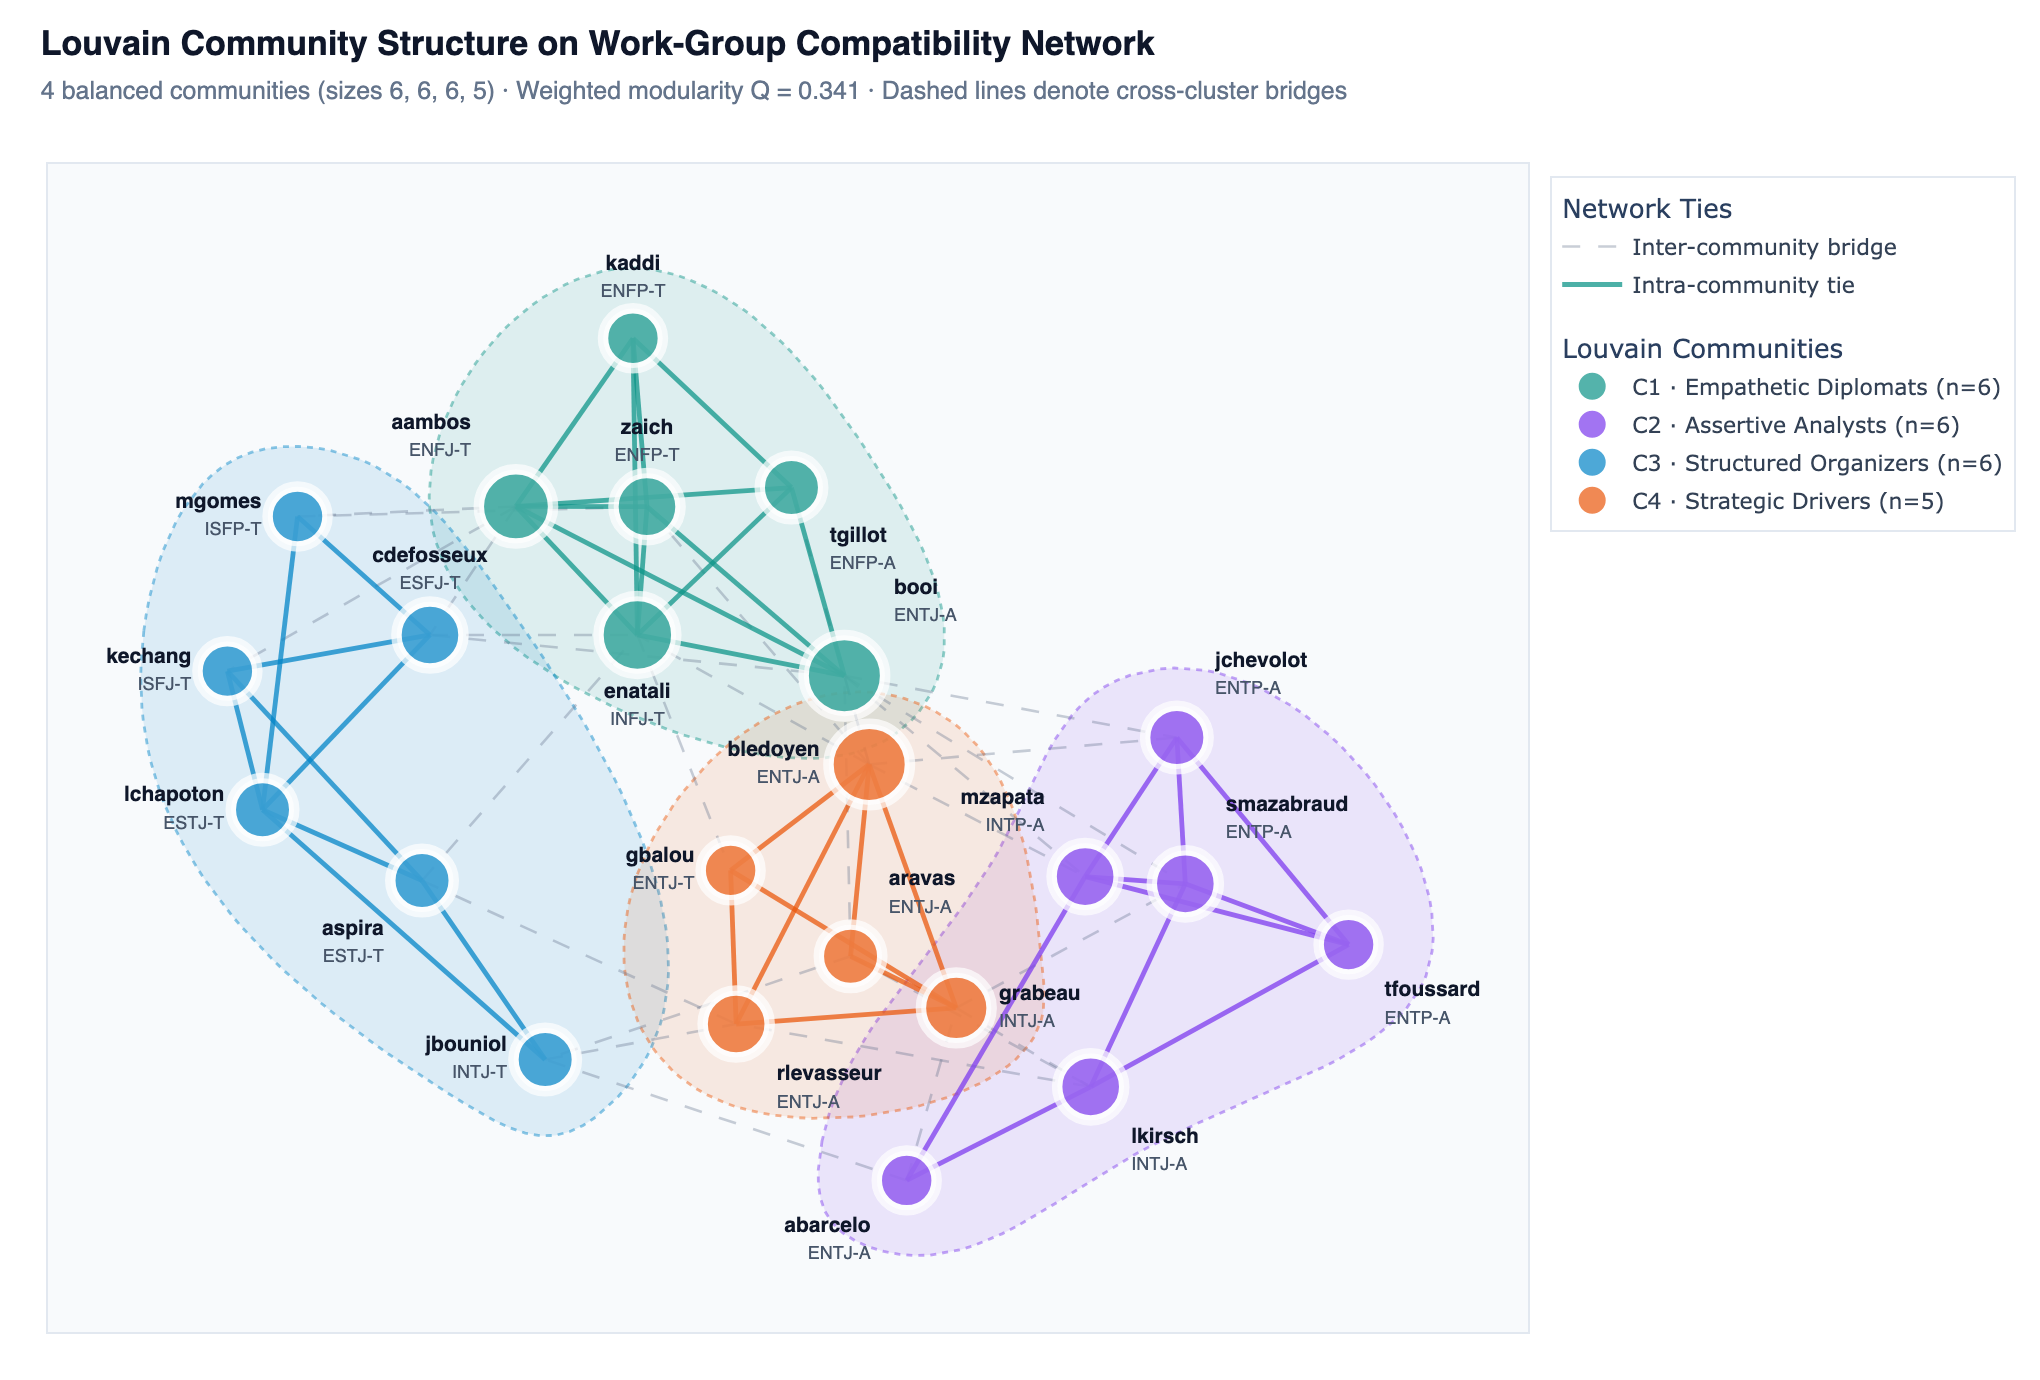

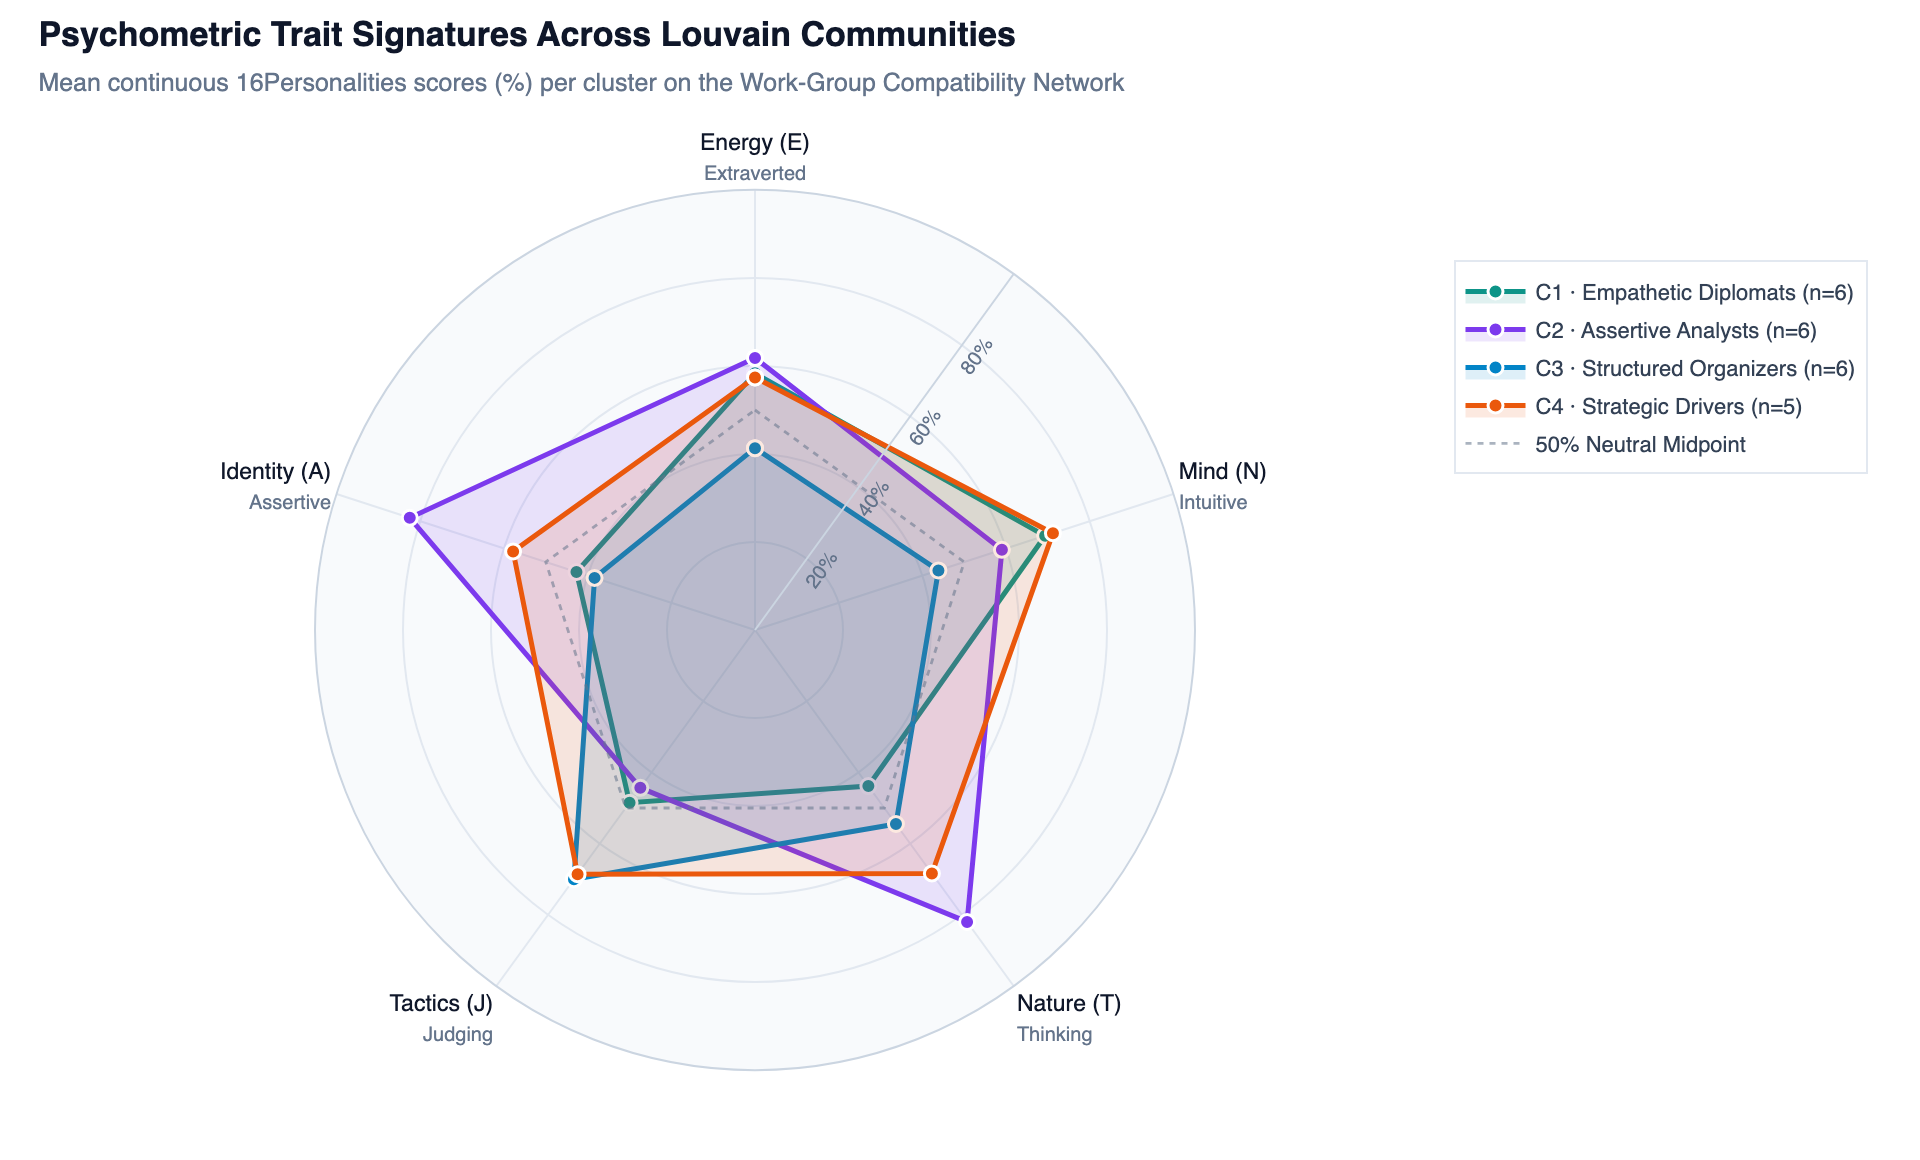

In [12]:
def smooth_hull_polygon(points, pad=0.08, n_interp=120):
    """Build a padded, C2-smooth closed spline boundary around a 2D node cluster."""
    pts = np.asarray(points, dtype=float)
    centroid = pts.mean(axis=0)
    if len(pts) == 1:
        theta = np.linspace(0, 2 * np.pi, n_interp)
        return centroid[0] + pad * np.cos(theta), centroid[1] + pad * np.sin(theta)
    if len(pts) == 2:
        vec = pts[1] - pts[0]
        unit = vec / max(np.linalg.norm(vec), 1e-6)
        perp = np.array([-unit[1], unit[0]])
        pts_hull = np.array([
            pts[0] - unit * pad + perp * pad,
            pts[1] + unit * pad + perp * pad,
            pts[1] + unit * pad - perp * pad,
            pts[0] - unit * pad - perp * pad,
        ])
    else:
        angles = np.linspace(0, 2 * np.pi, 12, endpoint=False)
        expanded = np.vstack([pts + pad * np.column_stack([np.cos(a), np.sin(a)]) for a in angles])
        hull = ConvexHull(expanded)
        pts_hull = expanded[hull.vertices]

    pts_closed = np.vstack([pts_hull, pts_hull[0]])
    tck, _ = splprep([pts_closed[:, 0], pts_closed[:, 1]], s=0.002, per=True, k=min(3, len(pts_hull) - 1))
    return splev(np.linspace(0, 1, n_interp), tck)


# Figure 7A — Compatibility Network Colored by Louvain Community with Smooth Hulls
fig_comm = go.Figure()
all_nodes = list(G_compat.nodes())
all_pts = np.array([pos_compat[n] for n in all_nodes])
span = max(all_pts[:, 0].max() - all_pts[:, 0].min(), all_pts[:, 1].max() - all_pts[:, 1].min())
text_pos_compat = smart_text_positions(pos_compat, all_nodes)
strength_compat = dict(G_compat.degree(weight="weight"))

for idx, comm in enumerate(compat_communities):
    _, fill_rgba, border_rgba, _ = CLUSTER_PALETTE[idx]
    hx, hy = smooth_hull_polygon([pos_compat[n] for n in comm], pad=0.082 * span)
    fig_comm.add_trace(
        go.Scatter(
            x=hx,
            y=hy,
            fill="toself",
            fillcolor=fill_rgba,
            mode="lines",
            line=dict(color=border_rgba, width=1.4, dash="dot"),
            hoverinfo="skip",
            showlegend=False,
        )
    )

inter_x, inter_y = [], []
for u, v in G_compat.edges():
    if node_to_community[u] != node_to_community[v]:
        inter_x.extend([pos_compat[u][0], pos_compat[v][0], None])
        inter_y.extend([pos_compat[u][1], pos_compat[v][1], None])

fig_comm.add_trace(
    go.Scatter(
        x=inter_x,
        y=inter_y,
        mode="lines",
        line=dict(width=1.3, color="rgba(100, 116, 139, 0.35)", dash="dash"),
        hoverinfo="skip",
        name="Inter-community bridge",
        legendgroup="Links",
        legendgrouptitle_text="Network Ties",
    )
)

for idx, comm in enumerate(compat_communities):
    _, _, border_rgba, _ = CLUSTER_PALETTE[idx]
    intra_x, intra_y = [], []
    for u, v in G_compat.subgraph(comm).edges():
        intra_x.extend([pos_compat[u][0], pos_compat[v][0], None])
        intra_y.extend([pos_compat[u][1], pos_compat[v][1], None])
    fig_comm.add_trace(
        go.Scatter(
            x=intra_x,
            y=intra_y,
            mode="lines",
            line=dict(width=2.4, color=border_rgba.replace("0.45", "0.74")),
            hoverinfo="skip",
            name="Intra-community tie" if idx == 0 else None,
            showlegend=(idx == 0),
            legendgroup="Links",
        )
    )

fig_comm.add_trace(
    go.Scatter(
        x=[pos_compat[n][0] for n in all_nodes],
        y=[pos_compat[n][1] for n in all_nodes],
        mode="markers",
        marker=dict(size=[27 + 1.8 * G_compat.degree(n) for n in all_nodes], color="#FFFFFF"),
        hoverinfo="skip",
        showlegend=False,
    )
)

for idx, comm in enumerate(compat_communities):
    solid, _, _, cname = CLUSTER_PALETTE[idx]
    c_nodes = sorted(comm)
    hover_data = [
        f"<b>{n}</b> · {df.loc[n, 'mbti']}{df.loc[n, 'variant']}<br>"
        f"Community: <b>{cname}</b><br>"
        f"Degree: <b>{G_compat.degree(n)}</b> · Strength: <b>{strength_compat[n]:.2f}</b><br>"
        f"<span style='color:#64748B'>E {df.loc[n, 'E']:.0%} · N {df.loc[n, 'N']:.0%} · "
        f"T {df.loc[n, 'T']:.0%} · J {df.loc[n, 'J']:.0%} · A {df.loc[n, 'A']:.0%}</span>"
        for n in c_nodes
    ]
    fig_comm.add_trace(
        go.Scatter(
            x=[pos_compat[n][0] for n in c_nodes],
            y=[pos_compat[n][1] for n in c_nodes],
            mode="markers+text",
            name=f"{cname} (n={len(c_nodes)})",
            legendgroup="Communities",
            legendgrouptitle_text="Louvain Communities" if idx == 0 else None,
            text=[
                f"<b>{n}</b><br><span style='font-size:9px;color:#475569'>{df.loc[n, 'mbti']}{df.loc[n, 'variant']}</span>"
                for n in c_nodes
            ],
            textposition=[text_pos_compat[n] for n in c_nodes],
            textfont=dict(size=10.5, color="#0F172A", family="Inter, -apple-system, sans-serif"),
            marker=dict(
                size=[20 + 1.8 * G_compat.degree(n) for n in c_nodes],
                color=solid,
                line=dict(width=2.5, color="#FFFFFF"),
            ),
            customdata=hover_data,
            hovertemplate="%{customdata}<extra></extra>",
        )
    )

xs, ys = all_pts[:, 0], all_pts[:, 1]
x_pad = (xs.max() - xs.min()) * 0.16
y_pad = (ys.max() - ys.min()) * 0.18

fig_comm.update_layout(
    title=dict(
        text=(
            "<b>Louvain Community Structure on Work-Group Compatibility Network</b>"
            f"<br><span style='font-size:12.5px;color:#64748B;font-weight:400'>"
            f"4 balanced communities (sizes 6, 6, 6, 5) · Weighted modularity Q = {compat_modularity:.3f} · Dashed lines denote cross-cluster bridges</span>"
        ),
        x=0.02, y=0.96, xanchor="left", yanchor="top",
        font=dict(size=17, color="#0F172A", family="Inter, -apple-system, sans-serif"),
    ),
    width=1020,
    height=690,
    paper_bgcolor="#FFFFFF",
    plot_bgcolor="#F8FAFC",
    margin=dict(l=24, r=250, t=82, b=24),
    xaxis=dict(showgrid=False, zeroline=False, showticklabels=False, range=[xs.min() - x_pad, xs.max() + x_pad], linecolor="#E2E8F0", linewidth=1, mirror=True),
    yaxis=dict(showgrid=False, zeroline=False, showticklabels=False, range=[ys.min() - y_pad, ys.max() + y_pad * 1.15], linecolor="#E2E8F0", linewidth=1, mirror=True),
    legend=dict(x=1.015, y=0.99, xanchor="left", yanchor="top", bgcolor="rgba(255,255,255,0.94)", bordercolor="#E2E8F0", borderwidth=1, font=dict(size=11, color="#334155"), tracegroupgap=12),
    hoverlabel=dict(bgcolor="#FFFFFF", bordercolor="#CBD5E1", font=dict(size=12, family="Inter, -apple-system, sans-serif", color="#0F172A")),
)
fig_comm.show()

# Figure 7B — Psychometric Radar Signatures Across Communities
trait_labels = [
    "Energy (E)<br><span style='font-size:10px;color:#64748B'>Extraverted</span>",
    "Mind (N)<br><span style='font-size:10px;color:#64748B'>Intuitive</span>",
    "Nature (T)<br><span style='font-size:10px;color:#64748B'>Thinking</span>",
    "Tactics (J)<br><span style='font-size:10px;color:#64748B'>Judging</span>",
    "Identity (A)<br><span style='font-size:10px;color:#64748B'>Assertive</span>",
]

fig_radar = go.Figure()
for idx, comm in enumerate(compat_communities):
    solid, fill_rgba, _, cname = CLUSTER_PALETTE[idx]
    means = [float(df.loc[sorted(comm), t].mean() * 100.0) for t in traits]
    fig_radar.add_trace(
        go.Scatterpolar(
            r=means + [means[0]],
            theta=trait_labels + [trait_labels[0]],
            fill="toself",
            fillcolor=fill_rgba.replace("0.11", "0.13"),
            mode="lines+markers",
            name=f"{cname} (n={len(comm)})",
            line=dict(color=solid, width=2.5),
            marker=dict(size=7.5, color=solid, line=dict(width=1.5, color="#FFFFFF")),
            hovertemplate=f"<b>{cname}</b><br>%{{theta}}: <b>%{{r:.1f}}%</b><extra></extra>",
        )
    )

fig_radar.add_trace(
    go.Scatterpolar(
        r=[50, 50, 50, 50, 50, 50],
        theta=trait_labels + [trait_labels[0]],
        mode="lines",
        name="50% Neutral Midpoint",
        line=dict(color="rgba(100, 116, 139, 0.55)", width=1.4, dash="dot"),
        hoverinfo="skip",
    )
)

fig_radar.update_layout(
    title=dict(
        text=(
            "<b>Psychometric Trait Signatures Across Louvain Communities</b>"
            "<br><span style='font-size:12.5px;color:#64748B;font-weight:400'>"
            "Mean continuous 16Personalities scores (%) per cluster on the Work-Group Compatibility Network</span>"
        ),
        x=0.02, y=0.96, xanchor="left", yanchor="top",
        font=dict(size=17, color="#0F172A", family="Inter, -apple-system, sans-serif"),
    ),
    width=960,
    height=580,
    paper_bgcolor="#FFFFFF",
    font=dict(family="Inter, -apple-system, sans-serif", color="#1E293B"),
    margin=dict(l=60, r=265, t=95, b=45),
    polar=dict(
        bgcolor="#F8FAFC",
        radialaxis=dict(
            visible=True,
            range=[0, 100],
            angle=54,
            tickangle=0,
            tickvals=[20, 40, 60, 80],
            ticktext=["20%", "40%", "60%", "80%"],
            tickfont=dict(size=10, color="#64748B"),
            gridcolor="#E2E8F0",
            linecolor="#CBD5E1",
        ),
        angularaxis=dict(
            tickfont=dict(size=11.5, color="#0F172A"),
            gridcolor="#E2E8F0",
            linecolor="#CBD5E1",
            direction="clockwise",
            rotation=90,
        ),
    ),
    legend=dict(
        x=1.05, y=0.92, xanchor="left", yanchor="top",
        bgcolor="rgba(255,255,255,0.95)", bordercolor="#E2E8F0", borderwidth=1,
        font=dict(size=11, color="#334155"),
    ),
    hoverlabel=dict(bgcolor="#FFFFFF", bordercolor="#CBD5E1", font=dict(size=12, family="Inter, -apple-system, sans-serif", color="#0F172A")),
)
fig_radar.show()

## 8. Optimal Work-Pair Assignment (Maximum-Weight Matching)

Beyond exploratory structure, a central operational goal of modeling student compatibility is forming **concrete, high-functioning project teams**. On a weighted graph $G = (V, E, w)$, pairing students to maximize total cohort compatibility is formulated as the **maximum-cardinality maximum-weight matching** problem, solved in polynomial time via Edmonds' Blossom algorithm (`nx.max_weight_matching` with `maxcardinality=True`).

Evaluating this assignment on `G_compat` ($4$-NN, 67 edges) reveals two noteworthy results:
1. **Lossless Sparsification**: The optimal 11-pair matching on our sparse $4$-NN graph achieves a total compatibility weight of **$9.576$** (mean **$87.1\%$**, minimum **$76.3\%$**), which is **strictly identical** to the global optimum obtained on the unpruned complete graph $K_{23}$ (253 edges). Retaining only 4 nearest neighbors per student therefore preserves 100% of globally optimal team pairings.
2. **Alignment with Community Structure & Odd-Cohort Resolution ($N = 23$)**: Because $N = 23$ is odd, a pure dyadic matching forms 11 pairs and leaves a single student unassigned (`kaddi`, `ENFP-T`). Attaching `kaddi` to the existing pair that maximizes mean three-way compatibility (`aambos` `ENFJ-T` + `enatali` `INFJ-T`, mean triad score **$84.5\%$**) yields a complete class allocation of **10 dyads + 1 triad**, of which **9 out of 11 teams stay entirely within the same Louvain community**.

In [13]:
# Compare maximum-weight matching on sparse 4-NN G_compat vs. complete graph K_23
G_complete = nx.Graph()
for i in range(len(students)):
    for j in range(i + 1, len(students)):
        G_complete.add_edge(students[i], students[j], weight=float(compat_matrix[i, j]))

matching_4nn = nx.max_weight_matching(G_compat, maxcardinality=True, weight="weight")
matching_complete = nx.max_weight_matching(G_complete, maxcardinality=True, weight="weight")

weights_4nn = [G_compat[u][v]["weight"] for u, v in matching_4nn]
weights_complete = [G_complete[u][v]["weight"] for u, v in matching_complete]

matching_benchmark_df = pd.DataFrame([
    {
        "Graph Candidate Space": "Sparse Compatibility Graph (4-NN)",
        "Available Edges": G_compat.number_of_edges(),
        "Matched Pairs": len(matching_4nn),
        "Total Compatibility Weight": round(float(sum(weights_4nn)), 3),
        "Mean Pair Compatibility (%)": round(100.0 * float(np.mean(weights_4nn)), 1),
        "Min Pair Compatibility (%)": round(100.0 * float(np.min(weights_4nn)), 1),
        "Max Pair Compatibility (%)": round(100.0 * float(np.max(weights_4nn)), 1),
    },
    {
        "Graph Candidate Space": "Complete Compatibility Graph (K_23)",
        "Available Edges": G_complete.number_of_edges(),
        "Matched Pairs": len(matching_complete),
        "Total Compatibility Weight": round(float(sum(weights_complete)), 3),
        "Mean Pair Compatibility (%)": round(100.0 * float(np.mean(weights_complete)), 1),
        "Min Pair Compatibility (%)": round(100.0 * float(np.min(weights_complete)), 1),
        "Max Pair Compatibility (%)": round(100.0 * float(np.max(weights_complete)), 1),
    },
])
display(matching_benchmark_df)

# Resolve odd cohort size (N = 23) into 10 dyads + 1 optimal triad
matched_nodes = {u for pair in matching_4nn for u in pair}
unmatched_student = sorted(set(G_compat.nodes()) - matched_nodes)[0]
u_idx = students.index(unmatched_student)

best_pair_for_triad = max(
    matching_4nn,
    key=lambda p: (
        G_compat[p[0]][p[1]]["weight"]
        + compat_matrix[u_idx, students.index(p[0])]
        + compat_matrix[u_idx, students.index(p[1])]
    ) / 3.0,
)
p0, p1 = sorted(best_pair_for_triad)
triad_members = sorted([p0, p1, unmatched_student])
triad_pairs = [
    (triad_members[0], triad_members[1]),
    (triad_members[0], triad_members[2]),
    (triad_members[1], triad_members[2]),
]
triad_mean_score = float(np.mean([compat_matrix[students.index(a), students.index(b)] for a, b in triad_pairs]))

team_rows = []
student_to_team_info = {}

sorted_dyads = sorted(
    [tuple(sorted(p)) for p in matching_4nn if tuple(sorted(p)) != (p0, p1)],
    key=lambda pair: G_compat[pair[0]][pair[1]]["weight"],
    reverse=True,
)

for rank, (u, v) in enumerate(sorted_dyads, start=1):
    w = G_compat[u][v]["weight"]
    same_comm = node_to_community[u] == node_to_community[v]
    c_label = (
        CLUSTER_PALETTE[node_to_community[u]][3].split(" · ")[0]
        if same_comm
        else f"{CLUSTER_PALETTE[node_to_community[u]][3].split(' · ')[0]} ↔ {CLUSTER_PALETTE[node_to_community[v]][3].split(' · ')[0]}"
    )
    team_name = f"Team {rank:02d} (Dyad)"
    student_to_team_info[u] = f"{team_name} with {v} ({w:.1%})"
    student_to_team_info[v] = f"{team_name} with {u} ({w:.1%})"
    team_rows.append({
        "Team": team_name,
        "Format": "Dyad (2)",
        "Members": f"{u} ({df.loc[u, 'mbti']}{df.loc[u, 'variant']}), {v} ({df.loc[v, 'mbti']}{df.loc[v, 'variant']})",
        "Cluster Alignment": f"Intra-{c_label}" if same_comm else f"Cross ({c_label})",
        "Compatibility (%)": round(100.0 * w, 1),
    })

triad_team_name = f"Team {len(sorted_dyads) + 1:02d} (Triad)"
for m in triad_members:
    others = [x for x in triad_members if x != m]
    student_to_team_info[m] = f"{triad_team_name} with {others[0]} & {others[1]} ({triad_mean_score:.1%})"

triad_comms = {node_to_community[m] for m in triad_members}
team_rows.append({
    "Team": triad_team_name,
    "Format": "Triad (3)",
    "Members": ", ".join(f"{m} ({df.loc[m, 'mbti']}{df.loc[m, 'variant']})" for m in triad_members),
    "Cluster Alignment": (
        f"Intra-{CLUSTER_PALETTE[next(iter(triad_comms))][3].split(' · ')[0]}"
        if len(triad_comms) == 1
        else "Cross-cluster"
    ),
    "Compatibility (%)": round(100.0 * triad_mean_score, 1),
})

team_assignment_df = pd.DataFrame(team_rows)
display(team_assignment_df)

,Graph Candidate Space,Available Edges,Matched Pairs,Total Compatibility Weight,Mean Pair Compatibility (%),Min Pair Compatibility (%),Max Pair Compatibility (%)
0,Sparse Compatibility Graph (4-NN),67,11,9.576,87.1,76.3,92.5
1,Complete Compatibility Graph (K_23),253,11,9.576,87.1,76.3,92.5


,Team,Format,Members,Cluster Alignment,Compatibility (%)
0,Team 01 (Dyad),Dyad (2),"aravas (ENTJ-A), grabeau (INTJ-A)",Intra-C4,92.5
1,Team 02 (Dyad),Dyad (2),"aspira (ESTJ-T), lchapoton (ESTJ-T)",Intra-C3,90.3
2,Team 03 (Dyad),Dyad (2),"cdefosseux (ESFJ-T), kechang (ISFJ-T)",Intra-C3,89.1
3,Team 04 (Dyad),Dyad (2),"bledoyen (ENTJ-A), gbalou (ENTJ-T)",Intra-C4,89.1
4,Team 05 (Dyad),Dyad (2),"mzapata (INTP-A), smazabraud (ENTP-A)",Intra-C2,88.6
5,Team 06 (Dyad),Dyad (2),"booi (ENTJ-A), tgillot (ENFP-A)",Intra-C1,88.6
6,Team 07 (Dyad),Dyad (2),"jbouniol (INTJ-T), rlevasseur (ENTJ-A)",Cross (C3 ↔ C4),87.2
7,Team 08 (Dyad),Dyad (2),"jchevolot (ENTP-A), tfoussard (ENTP-A)",Intra-C2,81.9
8,Team 09 (Dyad),Dyad (2),"mgomes (ISFP-T), zaich (ENFP-T)",Cross (C3 ↔ C1),81.8
9,Team 10 (Dyad),Dyad (2),"abarcelo (ENTJ-A), lkirsch (INTJ-A)",Intra-C2,76.3


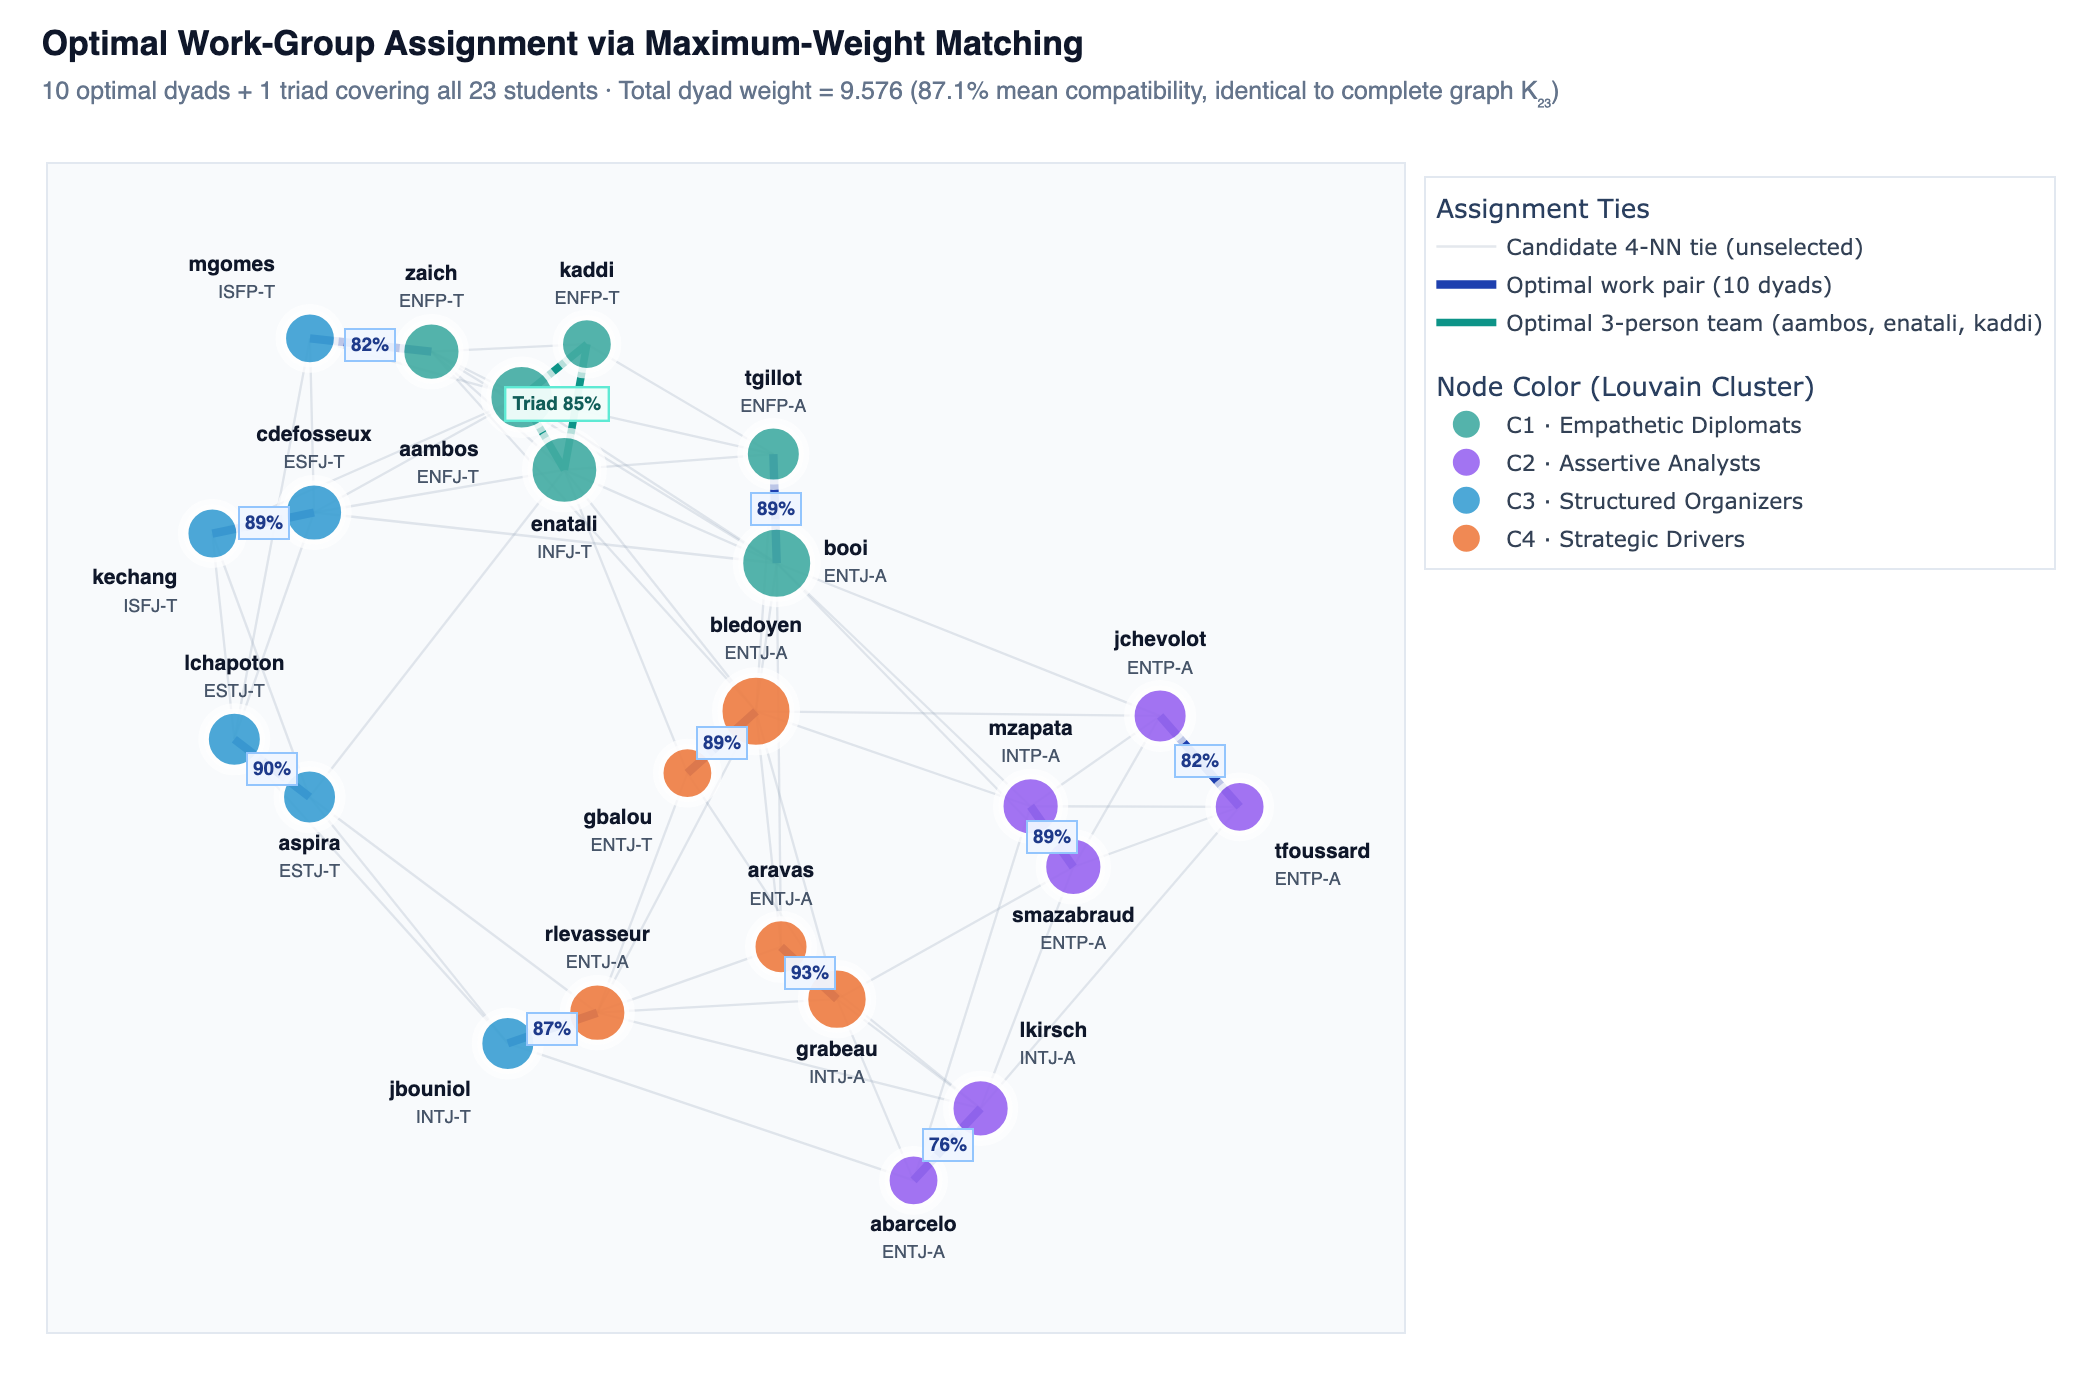

In [14]:
# Figure 8A — Optimal Work-Group Assignment Visualization
assigned_edge_set = set(sorted_dyads) | {tuple(sorted(e)) for e in triad_pairs}

G_layout = G_compat.copy()
for u, v in G_layout.edges():
    e = tuple(sorted((u, v)))
    G_layout[u][v]["lweight"] = (
        4.2 * G_compat[u][v]["weight"] if e in assigned_edge_set else 0.28 * G_compat[u][v]["weight"]
    )
for a, b in triad_pairs:
    if not G_layout.has_edge(a, b):
        G_layout.add_edge(a, b, lweight=3.8)

pos_match = nx.spring_layout(G_layout, pos=pos_compat, seed=42, k=0.82, iterations=90, weight="lweight")

dyad_x, dyad_y, mid_pts, mid_txt = [], [], [], []
for u, v in sorted_dyads:
    w = G_compat[u][v]["weight"]
    dyad_x.extend([pos_match[u][0], pos_match[v][0], None])
    dyad_y.extend([pos_match[u][1], pos_match[v][1], None])
    mid_pts.append((0.5 * (pos_match[u][0] + pos_match[v][0]), 0.5 * (pos_match[u][1] + pos_match[v][1])))
    mid_txt.append(f"<b>{w:.0%}</b>")

triad_cx = float(np.mean([pos_match[n][0] for n in triad_members]))
triad_cy = float(np.mean([pos_match[n][1] for n in triad_members]))
obstacle_pts = mid_pts + [(triad_cx, triad_cy)]

all_nodes = list(G_compat.nodes())
xs_arr = np.array([pos_match[n][0] for n in all_nodes])
ys_arr = np.array([pos_match[n][1] for n in all_nodes])
span_x = max(xs_arr.max() - xs_arr.min(), 1e-6)
span_y = max(ys_arr.max() - ys_arr.min(), 1e-6)
nx_c = {n: (pos_match[n][0] - xs_arr.min()) / span_x for n in all_nodes}
ny_c = {n: (pos_match[n][1] - ys_arr.min()) / span_y for n in all_nodes}
obs_norm = [((ox - xs_arr.min()) / span_x, (oy - ys_arr.min()) / span_y) for ox, oy in obstacle_pts]

candidates = [
    ("top center", (0.0, 0.060)),
    ("bottom center", (0.0, -0.064)),
    ("top left", (-0.055, 0.050)),
    ("top right", (0.055, 0.050)),
    ("bottom left", (-0.055, -0.054)),
    ("bottom right", (0.055, -0.054)),
    ("middle left", (-0.076, 0.0)),
    ("middle right", (0.076, 0.0)),
]
placed = list(obs_norm)
text_pos_match = {}
crowding = {u: min(np.hypot(nx_c[u] - nx_c[v], ny_c[u] - ny_c[v]) for v in all_nodes if v != u) for u in all_nodes}
for u in sorted(all_nodes, key=lambda n: crowding[n]):
    ux, uy = nx_c[u], ny_c[u]
    best_name, best_score, best_pt = "top center", -1e9, (ux, uy + 0.060)
    for idx, (cname, (dx, dy)) in enumerate(candidates):
        lx, ly = ux + dx, uy + dy
        min_nd = min(np.hypot((lx - nx_c[v]) / 1.35, (ly - ny_c[v]) / 0.85) for v in all_nodes if v != u)
        min_ld = min(np.hypot((lx - px) / 1.55, (ly - py) / 0.90) for px, py in placed)
        score = min(min_nd, min_ld) + (0.010 if idx == 0 else (0.005 if idx == 1 else 0.0))
        if score > best_score:
            best_score, best_name, best_pt = score, cname, (lx, ly)
    text_pos_match[u] = best_name
    placed.append(best_pt)

fig_match = go.Figure()

bg_x, bg_y = [], []
for u, v in G_compat.edges():
    if tuple(sorted((u, v))) not in assigned_edge_set:
        bg_x.extend([pos_match[u][0], pos_match[v][0], None])
        bg_y.extend([pos_match[u][1], pos_match[v][1], None])

fig_match.add_trace(
    go.Scatter(
        x=bg_x, y=bg_y, mode="lines",
        line=dict(width=1.15, color="rgba(148, 163, 184, 0.25)"),
        hoverinfo="skip", name="Candidate 4-NN tie (unselected)",
        legendgroup="Assignment", legendgrouptitle_text="Assignment Ties",
    )
)

fig_match.add_trace(
    go.Scatter(
        x=dyad_x, y=dyad_y, mode="lines",
        line=dict(width=4.2, color="#1E40AF"),
        hoverinfo="skip", name="Optimal work pair (10 dyads)",
        legendgroup="Assignment",
    )
)

trio_x, trio_y = [], []
for a, b in triad_pairs:
    trio_x.extend([pos_match[a][0], pos_match[b][0], None])
    trio_y.extend([pos_match[a][1], pos_match[b][1], None])

fig_match.add_trace(
    go.Scatter(
        x=trio_x, y=trio_y, mode="lines",
        line=dict(width=3.8, color="#0D9488"),
        hoverinfo="skip", name=f"Optimal 3-person team ({', '.join(triad_members)})",
        legendgroup="Assignment",
    )
)

fig_match.add_trace(
    go.Scatter(
        x=[pos_match[n][0] for n in all_nodes],
        y=[pos_match[n][1] for n in all_nodes],
        mode="markers",
        marker=dict(size=[27 + 1.6 * G_compat.degree(n) for n in all_nodes], color="#FFFFFF"),
        hoverinfo="skip", showlegend=False,
    )
)

for idx, comm in enumerate(compat_communities):
    solid, _, _, cname = CLUSTER_PALETTE[idx]
    c_nodes = sorted(comm)
    hover_assign = [
        f"<b>{n}</b> · {df.loc[n, 'mbti']}{df.loc[n, 'variant']}<br>"
        f"Assignment: <b>{student_to_team_info[n]}</b><br>"
        f"Community: {cname}"
        for n in c_nodes
    ]
    fig_match.add_trace(
        go.Scatter(
            x=[pos_match[n][0] for n in c_nodes],
            y=[pos_match[n][1] for n in c_nodes],
            mode="markers+text",
            name=cname,
            legendgroup="Communities",
            legendgrouptitle_text="Node Color (Louvain Cluster)" if idx == 0 else None,
            text=[
                f"<b>{n}</b><br><span style='font-size:9px;color:#475569'>{df.loc[n, 'mbti']}{df.loc[n, 'variant']}</span>"
                for n in c_nodes
            ],
            textposition=[text_pos_match[n] for n in c_nodes],
            textfont=dict(size=10.5, color="#0F172A", family="Inter, -apple-system, sans-serif"),
            marker=dict(size=[20 + 1.6 * G_compat.degree(n) for n in c_nodes], color=solid, line=dict(width=2.5, color="#FFFFFF")),
            customdata=hover_assign,
            hovertemplate="%{customdata}<extra></extra>",
        )
    )

score_annotations = [
    dict(
        x=mx, y=my, text=mtxt, showarrow=False,
        font=dict(size=9.5, color="#1E3A8A", family="Inter, -apple-system, sans-serif"),
        bgcolor="rgba(239, 246, 255, 0.95)", bordercolor="#93C5FD", borderwidth=1, borderpad=2.5,
    )
    for (mx, my), mtxt in zip(mid_pts, mid_txt)
] + [
    dict(
        x=triad_cx, y=triad_cy, text=f"<b>Triad {triad_mean_score:.0%}</b>", showarrow=False,
        font=dict(size=9.5, color="#115E59", family="Inter, -apple-system, sans-serif"),
        bgcolor="rgba(240, 253, 250, 0.96)", bordercolor="#5EEAD4", borderwidth=1.2, borderpad=3,
    )
]

x_pad, y_pad = span_x * 0.16, span_y * 0.18
fig_match.update_layout(
    title=dict(
        text=(
            "<b>Optimal Work-Group Assignment via Maximum-Weight Matching</b>"
            f"<br><span style='font-size:12.5px;color:#64748B;font-weight:400'>"
            f"10 optimal dyads + 1 triad covering all 23 students · Total dyad weight = {sum(weights_4nn):.3f} "
            f"({100.0 * np.mean(weights_4nn):.1f}% mean compatibility, identical to complete graph K₂₃)</span>"
        ),
        x=0.02, y=0.96, xanchor="left", yanchor="top",
        font=dict(size=17, color="#0F172A", family="Inter, -apple-system, sans-serif"),
    ),
    width=1040, height=690,
    annotations=score_annotations,
    paper_bgcolor="#FFFFFF", plot_bgcolor="#F8FAFC",
    margin=dict(l=24, r=280, t=82, b=24),
    xaxis=dict(showgrid=False, zeroline=False, showticklabels=False, range=[xs_arr.min() - x_pad, xs_arr.max() + x_pad], linecolor="#E2E8F0", linewidth=1, mirror=True),
    yaxis=dict(showgrid=False, zeroline=False, showticklabels=False, range=[ys_arr.min() - y_pad, ys_arr.max() + y_pad * 1.15], linecolor="#E2E8F0", linewidth=1, mirror=True),
    legend=dict(x=1.015, y=0.99, xanchor="left", yanchor="top", bgcolor="rgba(255,255,255,0.94)", bordercolor="#E2E8F0", borderwidth=1, font=dict(size=11, color="#334155"), tracegroupgap=12),
    hoverlabel=dict(bgcolor="#FFFFFF", bordercolor="#CBD5E1", font=dict(size=12, family="Inter, -apple-system, sans-serif", color="#0F172A")),
)
fig_match.show()

## 9. Interactive Network Explorer (`graph.html`)

Finally, we export `G_compat` to a standalone interactive web application (`graph.html`) enriched with Louvain community colors, assigned optimal team partnerships, and interactive view filters (full $4$-NN topology, optimal teams only, or individual Louvain communities).

In [15]:
from pyvis.network import Network

net = Network(
    height="100vh",
    width="100%",
    bgcolor="#F8FAFC",
    font_color="#0F172A",
    cdn_resources="in_line",
)
net.barnes_hut(gravity=-4200, central_gravity=0.28, spring_length=155, spring_strength=0.045, damping=0.22)

for node, attrs in G_compat.nodes(data=True):
    comm_idx = node_to_community[node]
    solid_color, _, _, comm_label = CLUSTER_PALETTE[comm_idx]
    tooltip = (
        f"{node} ({attrs['mbti']}{attrs['variant']})\n"
        f"Community: {comm_label}\n"
        f"Optimal Team: {student_to_team_info[node]}\n"
        f"Degree: {G_compat.degree(node)} | Strength: {strength_compat[node]:.2f}\n"
        f"E: {attrs['E']:.0%} | N: {attrs['N']:.0%} | T: {attrs['T']:.0%} | "
        f"J: {attrs['J']:.0%} | A: {attrs['A']:.0%}"
    )
    net.add_node(
        node,
        label=f"{node}\n({attrs['mbti']}{attrs['variant']})",
        title=tooltip,
        size=18 + 2.2 * G_compat.degree(node),
        shape="dot",
        color={
            "background": solid_color,
            "border": "#FFFFFF",
            "highlight": {"background": solid_color, "border": "#0F172A"},
            "hover": {"background": solid_color, "border": "#0F172A"},
        },
        borderWidth=3,
        font={"size": 13, "face": "Inter, -apple-system, BlinkMacSystemFont, sans-serif", "color": "#0F172A"},
        community=comm_idx,
    )

for u, v, attrs in G_compat.edges(data=True):
    w = attrs["weight"]
    e_key = tuple(sorted((u, v)))
    is_optimal = e_key in assigned_edge_set
    is_triad = e_key in {tuple(sorted(p)) for p in triad_pairs}
    edge_color = "#0D9488" if is_triad else ("#1E40AF" if is_optimal else "rgba(148, 163, 184, 0.42)")
    net.add_edge(
        u,
        v,
        width=4.2 if is_optimal else 1.5,
        color={"color": edge_color, "highlight": "#0F172A", "hover": "#334155"},
        title=f"{u} ↔ {v} | Compatibility: {w:.1%}" + (" (Optimal Team Tie)" if is_optimal else ""),
        optimal=is_optimal,
    )

# Add missing triad closure edge if not already in 4-NN so the triad is complete in Team View
for a, b in triad_pairs:
    if not G_compat.has_edge(a, b):
        w_ab = float(compat_matrix[students.index(a), students.index(b)])
        net.add_edge(
            a,
            b,
            width=3.6,
            dashes=True,
            color={"color": "#0D9488", "highlight": "#0F172A", "hover": "#0D9488"},
            title=f"{a} ↔ {b} | Compatibility: {w_ab:.1%} (Triad Closure Tie)",
            optimal=True,
        )

html_content = net.generate_html()

ui_overlay = f"""
<style>
  html, body {{ margin: 0; padding: 0; overflow: hidden; background: #F8FAFC; font-family: Inter, -apple-system, BlinkMacSystemFont, "Segoe UI", Roboto, sans-serif; }}
  .card {{ border: none !important; }}
  #mynetwork {{ border: none !important; height: 100vh !important; width: 100vw !important; background: #F8FAFC !important; }}
  .hud-panel {{
    position: fixed; top: 20px; left: 20px; z-index: 999; width: 310px;
    background: rgba(255, 255, 255, 0.92); backdrop-filter: blur(12px); -webkit-backdrop-filter: blur(12px);
    border: 1px solid #E2E8F0; border-radius: 14px; padding: 16px 18px;
    box-shadow: 0 10px 25px -5px rgba(15, 23, 42, 0.08);
  }}
  .hud-title {{ font-size: 15px; font-weight: 700; color: #0F172A; margin: 0 0 4px 0; letter-spacing: -0.01em; }}
  .hud-sub {{ font-size: 11.5px; color: #64748B; margin: 0 0 12px 0; line-height: 1.4; }}
  .hud-kpis {{ display: grid; grid-template-columns: repeat(3, 1fr); gap: 6px; margin-bottom: 14px; }}
  .kpi-box {{ background: #F8FAFC; border: 1px solid #E2E8F0; border-radius: 8px; padding: 6px 8px; text-align: center; }}
  .kpi-val {{ font-size: 13px; font-weight: 700; color: #0F172A; display: block; }}
  .kpi-lbl {{ font-size: 10px; color: #64748B; }}
  .hud-sec {{ font-size: 10.5px; font-weight: 600; text-transform: uppercase; letter-spacing: 0.05em; color: #475569; margin: 10px 0 6px 0; }}
  .btn-row {{ display: flex; gap: 6px; margin-bottom: 8px; }}
  .hud-btn {{
    flex: 1; padding: 6px 8px; font-size: 11.5px; font-weight: 600; border-radius: 8px; cursor: pointer;
    border: 1px solid #CBD5E1; background: #FFFFFF; color: #334155; transition: all 0.15s ease;
  }}
  .hud-btn:hover {{ background: #F1F5F9; }}
  .hud-btn.active {{ background: #0F172A; color: #FFFFFF; border-color: #0F172A; }}
  .comm-list {{ display: flex; flex-direction: column; gap: 5px; }}
  .comm-item {{
    display: flex; align-items: center; gap: 8px; font-size: 11.5px; color: #1E293B;
    padding: 5px 8px; border-radius: 7px; cursor: pointer; transition: background 0.15s ease;
  }}
  .comm-item:hover {{ background: #F1F5F9; }}
  .comm-dot {{ width: 10px; height: 10px; border-radius: 50%; flex-shrink: 0; }}
</style>
<div class="hud-panel">
  <div class="hud-title">MBTI Compatibility Network</div>
  <div class="hud-sub">5D Ideal-Partner 4-NN Graph · Albert School</div>
  <div class="hud-kpis">
    <div class="kpi-box"><span class="kpi-val">{G_compat.number_of_nodes()}</span><span class="kpi-lbl">Students</span></div>
    <div class="kpi-box"><span class="kpi-val">{compat_modularity:.3f}</span><span class="kpi-lbl">Modularity Q</span></div>
    <div class="kpi-box"><span class="kpi-val">{100.0 * np.mean(weights_4nn):.1f}%</span><span class="kpi-lbl">Mean Pair Fit</span></div>
  </div>
  <div class="hud-sec">Edge View Mode</div>
  <div class="btn-row">
    <button id="btn-all" class="hud-btn active" onclick="setEdgeMode('all')">Full 4-NN ({G_compat.number_of_edges()})</button>
    <button id="btn-opt" class="hud-btn" onclick="setEdgeMode('optimal')">Optimal Teams (11)</button>
  </div>
  <div class="hud-sec">Louvain Communities (Click to Focus)</div>
  <div class="comm-list">
    <div class="comm-item" onclick="focusCommunity(null)"><span class="comm-dot" style="background:#64748B"></span><span>Show All Communities</span></div>
    <div class="comm-item" onclick="focusCommunity(0)"><span class="comm-dot" style="background:{CLUSTER_PALETTE[0][0]}"></span><span>{CLUSTER_PALETTE[0][3]} (6)</span></div>
    <div class="comm-item" onclick="focusCommunity(1)"><span class="comm-dot" style="background:{CLUSTER_PALETTE[1][0]}"></span><span>{CLUSTER_PALETTE[1][3]} (6)</span></div>
    <div class="comm-item" onclick="focusCommunity(2)"><span class="comm-dot" style="background:{CLUSTER_PALETTE[2][0]}"></span><span>{CLUSTER_PALETTE[2][3]} (6)</span></div>
    <div class="comm-item" onclick="focusCommunity(3)"><span class="comm-dot" style="background:{CLUSTER_PALETTE[3][0]}"></span><span>{CLUSTER_PALETTE[3][3]} (5)</span></div>
  </div>
</div>
<script>
  function setEdgeMode(mode) {{
    document.getElementById('btn-all').classList.toggle('active', mode === 'all');
    document.getElementById('btn-opt').classList.toggle('active', mode === 'optimal');
    const updates = [];
    edges.forEach(function(e) {{
      updates.push({{ id: e.id, hidden: (mode === 'optimal' && !e.optimal) }});
    }});
    edges.update(updates);
  }}
  function focusCommunity(cIdx) {{
    const updates = [];
    nodes.forEach(function(n) {{
      const dim = (cIdx !== null && n.community !== cIdx);
      updates.push({{
        id: n.id,
        color: dim ? {{ background: 'rgba(203, 213, 225, 0.35)', border: '#F8FAFC' }} : nodeColors[n.id],
        font: {{ color: dim ? 'rgba(15, 23, 42, 0.22)' : '#0F172A' }}
      }});
    }});
    nodes.update(updates);
  }}
</script>
"""

html_content = html_content.replace("</body>", ui_overlay + "\n</body>")
with open("graph.html", "w", encoding="utf-8") as f:
    f.write(html_content)

print("Saved redesigned interactive explorer to graph.html")

Saved redesigned interactive explorer to graph.html
